In [63]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as ms
import sklearn
from scipy import stats
import glob
%matplotlib inline

print('Done Setup')

Done Setup


# A = data Acquistion 

In [64]:


# List of your 20 company symbols or CSV filenames
tickers = ['NABIL', 'EBL', 'NIMB', 'ADBL', 'NTC', 'NLIC', 'LICN', 'AHPC', 
           'CHCL', 'SHPC', 'GBIME', 'SCB', 'HDL', 'STC', 'NFS', 'CIT', 
           'TPC', 'BBC', 'CZBIL', 'KBL']

# Option A: If your data is in separate CSV files named after the ticker (e.g., 'NABIL.csv')
dfs = []
for ticker in tickers:
    # Read individual CSV file
    df = pd.read_csv(f"{ticker}.csv")
    
    # Add a column to identify the company
    df['Company'] = ticker
    
    # Ensure Date column is in datetime format
    df['published_date'] = pd.to_datetime(df['published_date'])
    
    dfs.append(df)

# Combine all dataframes into a single master dataframe
nepse_data = pd.concat(dfs, ignore_index=True)

# Sort by Date and Company
nepse_date = nepse_data.sort_values(by=['published_date', 'Company']).reset_index(drop=True)

nepse_data.head(10)

,published_date,open,high,low,close,per_change,traded_quantity,traded_amount,status,Company
0,2011-05-15,1091.0,1155.0,1112.0,1155.0,NaN,38.0,43057.0,0,NABIL
1,2011-05-16,1155.0,1193.0,1160.0,1193.0,3.29,156.0,183026.0,0,NABIL
2,2011-05-18,1193.0,1172.0,1150.0,1172.0,-1.76,939.0,1087972.0,0,NABIL
3,2011-05-19,1172.0,1194.0,1155.0,1194.0,1.88,490.0,573992.0,0,NABIL
4,2011-05-22,1194.0,1193.0,1178.0,1178.0,-1.34,115.0,135930.0,0,NABIL
5,2011-05-23,1178.0,1189.0,1165.0,1170.0,-0.68,239.0,279927.0,0,NABIL
6,2011-05-24,1170.0,1160.0,1150.0,1150.0,-1.71,282.0,325456.0,0,NABIL
7,2011-05-25,1150.0,1159.0,1100.0,1150.0,0.00,597.0,664216.0,0,NABIL
8,2011-05-26,1150.0,1149.0,1127.0,1149.0,-0.09,127.0,143553.0,0,NABIL
9,2011-05-30,1149.0,1151.0,1140.0,1150.0,0.09,320.0,366010.0,0,NABIL


In [65]:
nepse_data.describe(include='all').T

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
published_date,58535,NaN,NaN,NaN,2019-06-22 03:40:44.506705,1995-07-20 00:00:00,2015-09-30 00:00:00,2020-01-05 00:00:00,2023-08-02 00:00:00,2026-10-16 00:00:00,NaN
open,58535.0,NaN,NaN,NaN,1179.878917,88.0,351.25,650.0,1520.0,13320.0,1323.151653
high,58535.0,NaN,NaN,NaN,1195.629074,0.0,357.45,659.0,1541.0,13780.0,1344.115606
low,58535.0,NaN,NaN,NaN,1162.803993,0.0,345.1,642.0,1500.0,12501.0,1301.734006
close,58535.0,NaN,NaN,NaN,1178.6934,0.0,351.0,650.0,1520.0,13317.0,1321.487762
per_change,58521.0,NaN,NaN,NaN,0.067899,-76.34,-0.96,0.0,0.81,330.48,2.869575
traded_quantity,58535.0,NaN,NaN,NaN,39276.288169,1.0,2370.5,9809.0,34470.5,3546853.0,101533.52665
traded_amount,58535.0,NaN,NaN,NaN,22708908.86715,0.0,2008851.65,7472196.5,21573510.25,1757930386.0,52134083.962664
status,58535.0,NaN,NaN,NaN,-0.085487,-1.0,-1.0,0.0,1.0,1.0,0.762592
Company,58535,20,CHCL,4479,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [66]:
nepse_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 58535 entries, 0 to 58534
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   published_date   58535 non-null  datetime64[us]
 1   open             58535 non-null  float64       
 2   high             58535 non-null  float64       
 3   low              58535 non-null  float64       
 4   close            58535 non-null  float64       
 5   per_change       58521 non-null  float64       
 6   traded_quantity  58535 non-null  float64       
 7   traded_amount    58535 non-null  float64       
 8   status           58535 non-null  int64         
 9   Company          58535 non-null  str           
dtypes: datetime64[us](1), float64(7), int64(1), str(1)
memory usage: 4.5 MB


## null values

In [67]:
nepse_data.isna().sum()

published_date      0
open                0
high                0
low                 0
close               0
per_change         14
traded_quantity     0
traded_amount       0
status              0
Company             0
dtype: int64

### null valeues discription
- per_change = NaN, meaning the company has just started

### null graph

<Axes: >

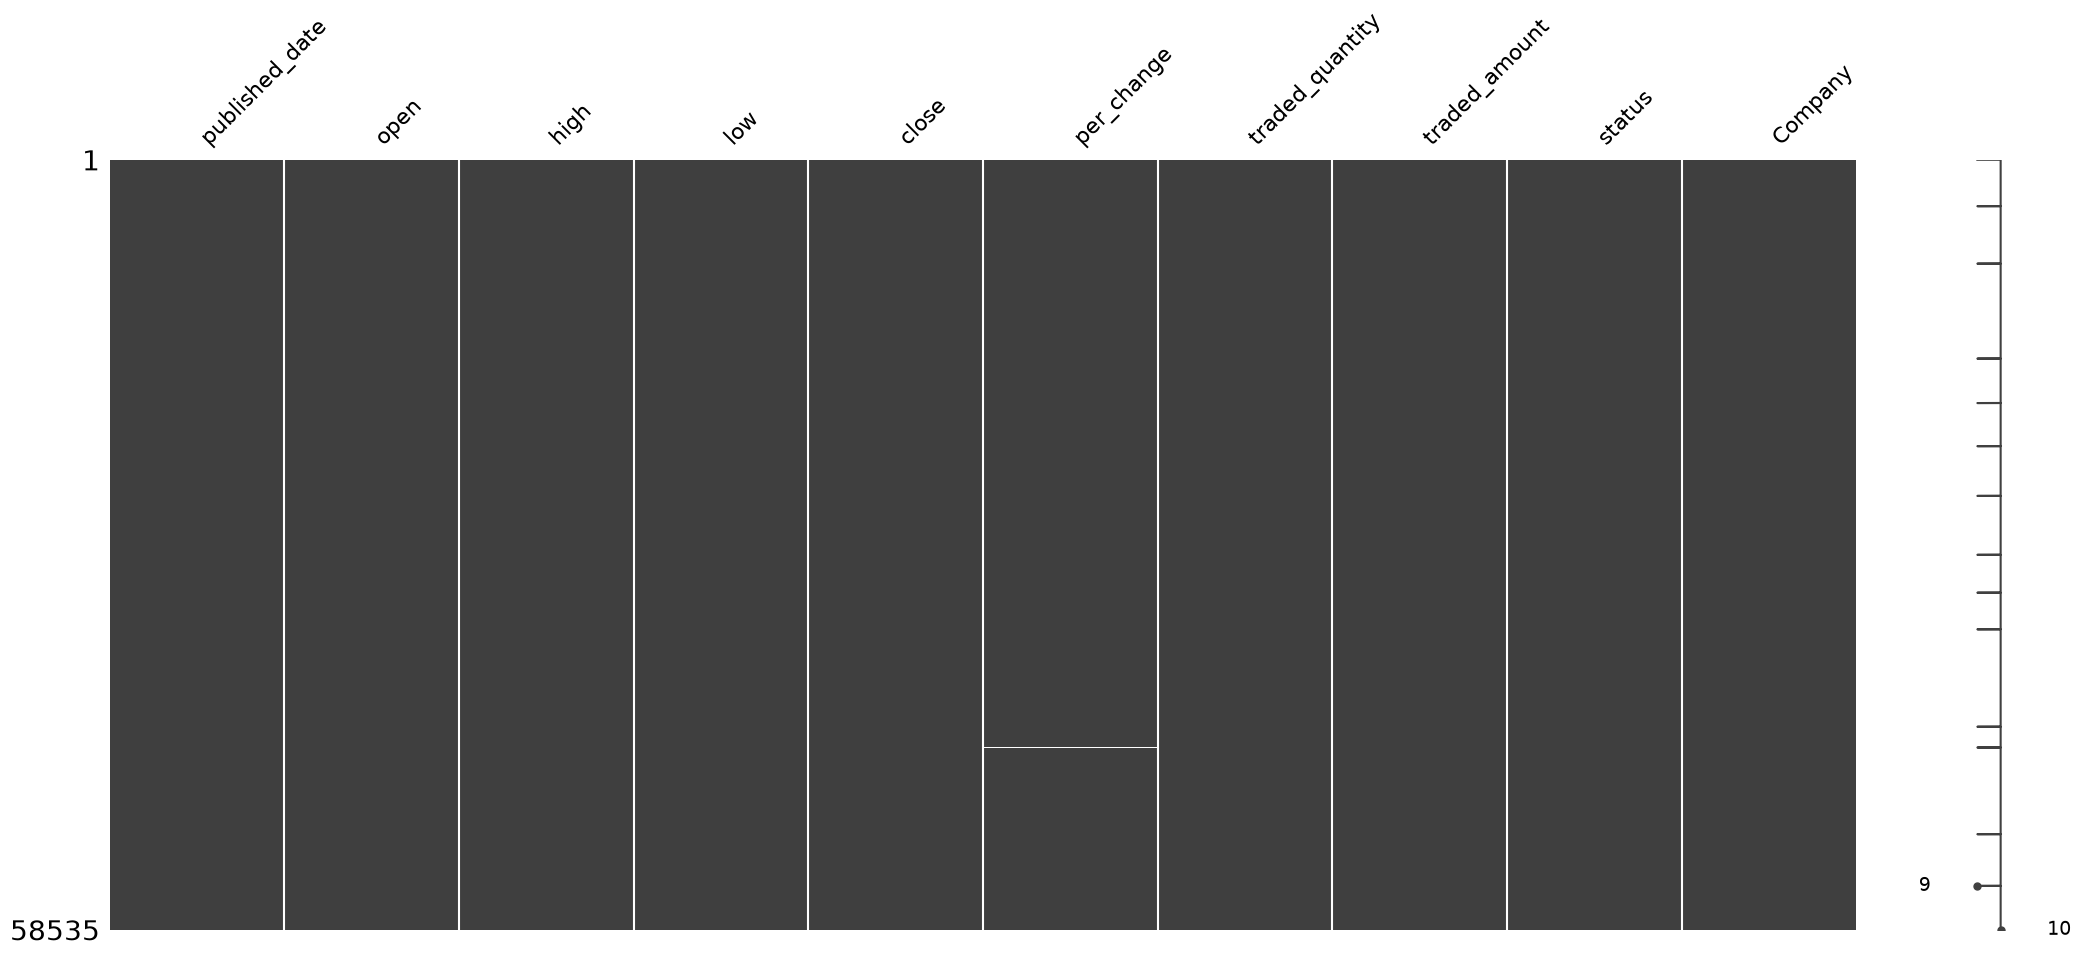

In [68]:
ms.matrix(nepse_data)

In [69]:
nepse_data.shape

(58535, 10)

# F = Data Filter

## company data fiter

In [70]:
nepse_data['Company'].value_counts()

Company
CHCL     4479
CZBIL    3929
AHPC     3779
ADBL     3679
NTC      3539
NABIL    3529
EBL      3529
SCB      3529
NLIC     3379
KBL      3337
LICN     3279
CIT      3079
SHPC     2879
GBIME    2785
BBC      2386
HDL      2249
STC      1627
NFS      1579
TPC      1126
NIMB      838
Name: count, dtype: int64

In [135]:
nepse_copy.columns

Index(['open', 'high', 'low', 'close', 'per_change', 'traded_quantity',
       'traded_amount', 'status', 'Company', 'year', 'month', 'day', 'macd',
       'macd_signal', 'macd_histogram', 'amount_sma20', 'strength_multiplier',
       'temp_date', 'vol_sma20', 'vol_strength', 'signal', 'daily_return',
       'strategy_return', 'cumulative_growth'],
      dtype='str')

### pie-chart

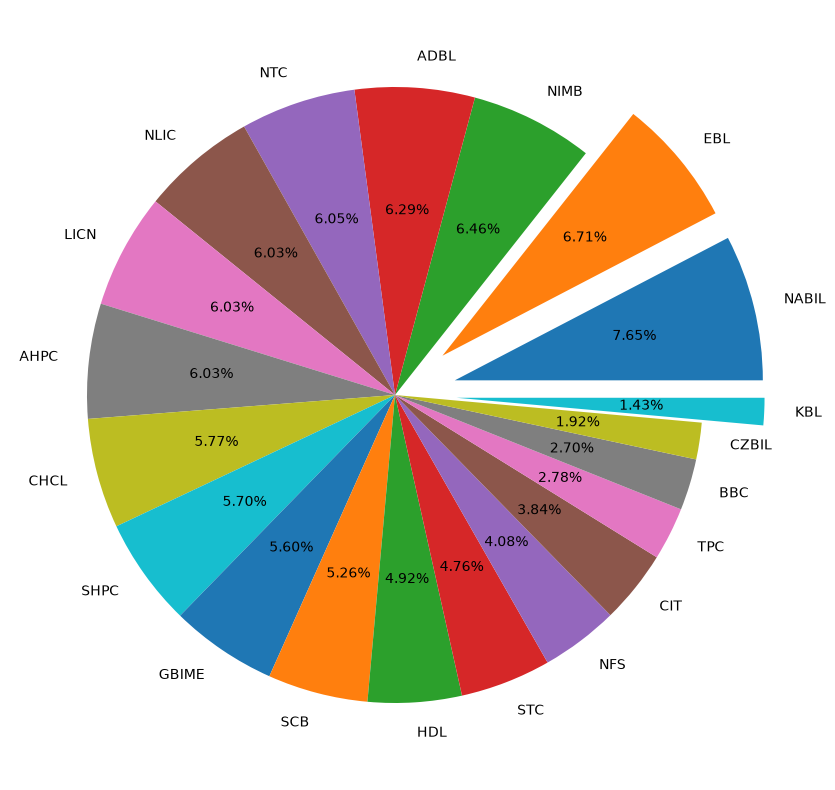

In [71]:
# pie-chatt
plt.figure(figsize = (10, 10))
explode = [0.2,0.2,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.2]
plt.pie(nepse_data['Company'].value_counts(), autopct='%1.2f%%', labels=tickers, explode= explode)
plt.show()

### bar graphy traded amount

In [72]:
nepse_data.groupby('Company')['traded_amount'].sum()

Company
ADBL     4.198486e+10
AHPC     1.092338e+11
BBC      5.384256e+09
CHCL     6.757345e+10
CIT      6.428358e+10
CZBIL    4.565516e+10
EBL      7.923509e+10
GBIME    8.283032e+10
HDL      1.293306e+11
KBL      9.335805e+10
LICN     4.147640e+10
NABIL    1.130294e+11
NFS      4.836118e+10
NIMB     2.442536e+10
NLIC     1.303170e+11
NTC      7.979033e+10
SCB      4.151074e+10
SHPC     9.523768e+10
STC      2.211366e+10
TPC      1.413496e+10
Name: traded_amount, dtype: float64

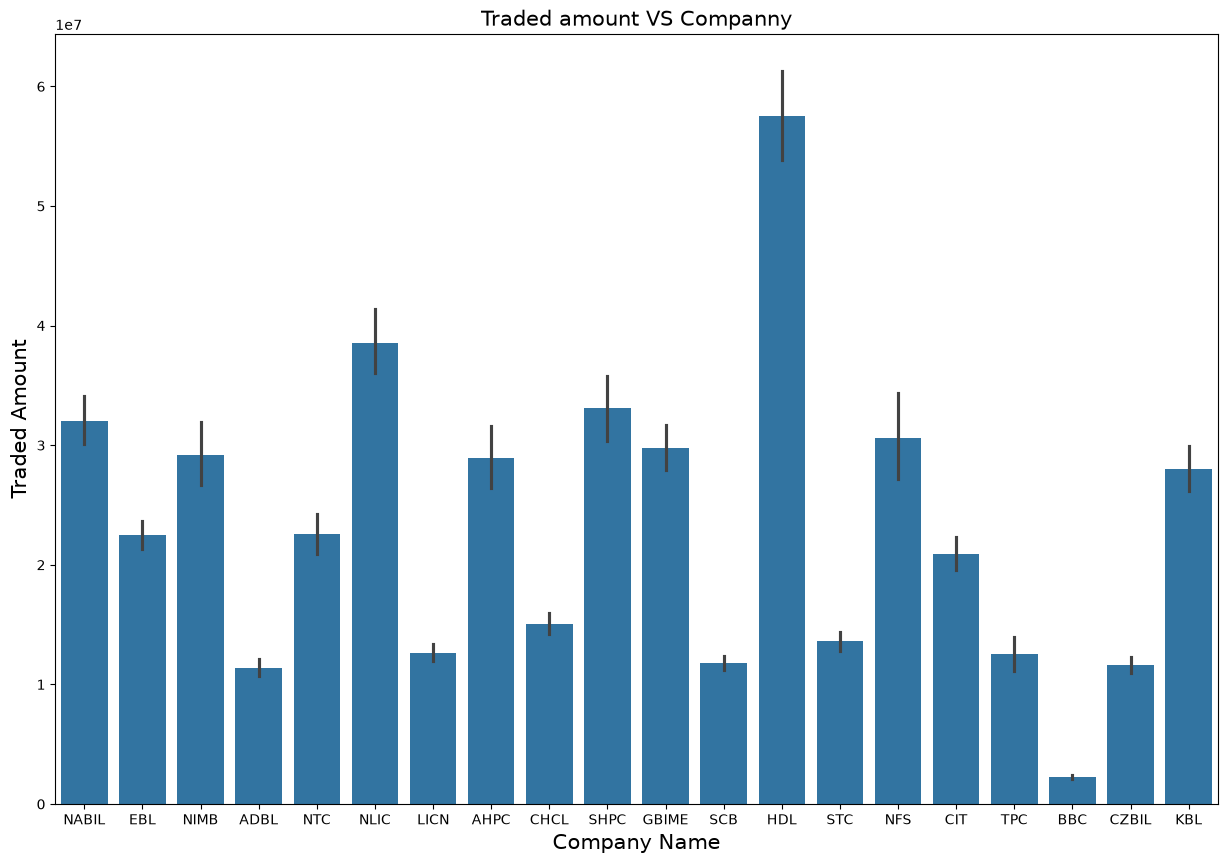

In [73]:
plt.figure(figsize = (15,10))
sns.barplot(data = nepse_data, x = 'Company', y = 'traded_amount' )
plt.xlabel( 'Company Name', fontsize = 15)
plt.ylabel('Traded Amount', fontsize = 15)
plt.title('Traded amount VS Companny', fontsize = 15)
plt.show()

### bar graph for traded quantity

In [74]:
nepse_data.groupby('Company')['traded_quantity'].sum()

Company
ADBL     104994539.0
AHPC     311907437.0
BBC        1306046.0
CHCL     104783612.0
CIT       23197745.0
CZBIL    155188672.0
EBL       92678757.0
GBIME    267867589.0
HDL       62418623.0
KBL      388106166.0
LICN      26253519.0
NABIL    125662746.0
NFS       63006312.0
NIMB     116193556.0
NLIC      99452685.0
NTC       77811554.0
SCB       49810214.0
SHPC     192408738.0
STC        4117334.0
TPC       31871684.0
Name: traded_quantity, dtype: float64

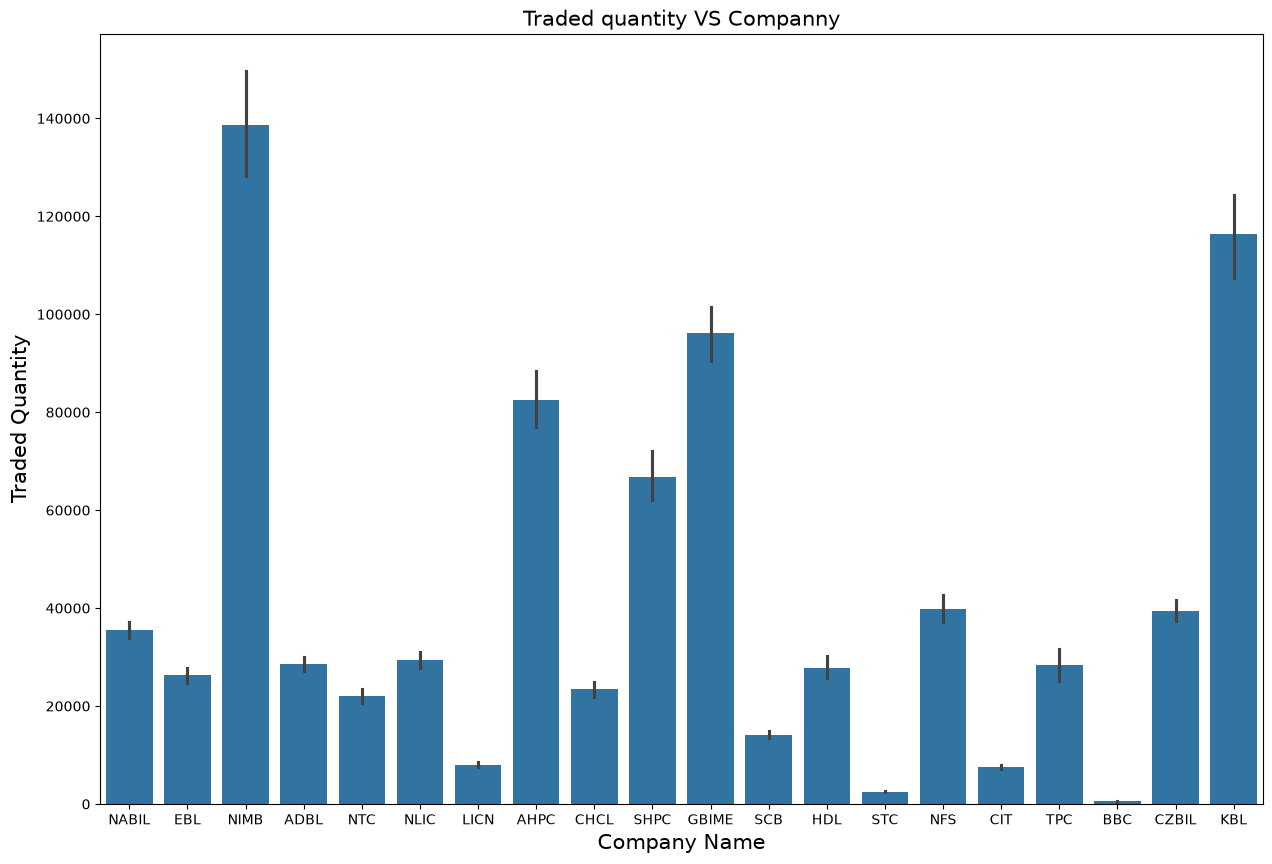

In [75]:
plt.figure(figsize = (15,10))
sns.barplot(data = nepse_data, x = 'Company', y = 'traded_quantity' )
plt.xlabel( 'Company Name', fontsize = 15)
plt.ylabel('Traded Quantity', fontsize = 15)
plt.title('Traded quantity VS Companny', fontsize = 15)
plt.show()

## seperatiing published_date into year month and day


In [76]:
nepse_copy = nepse_data.copy()

nepse_copy['year'] = pd.to_datetime(nepse_copy['published_date']).dt.year
nepse_copy['month'] = pd.to_datetime(nepse_copy['published_date']).dt.month
nepse_copy['day'] = pd.to_datetime(nepse_copy['published_date']).dt.day

nepse_copy.head()

,published_date,open,high,low,close,per_change,traded_quantity,traded_amount,status,Company,year,month,day
0,2011-05-15,1091.0,1155.0,1112.0,1155.0,NaN,38.0,43057.0,0,NABIL,2011,5,15
1,2011-05-16,1155.0,1193.0,1160.0,1193.0,3.29,156.0,183026.0,0,NABIL,2011,5,16
2,2011-05-18,1193.0,1172.0,1150.0,1172.0,-1.76,939.0,1087972.0,0,NABIL,2011,5,18
3,2011-05-19,1172.0,1194.0,1155.0,1194.0,1.88,490.0,573992.0,0,NABIL,2011,5,19
4,2011-05-22,1194.0,1193.0,1178.0,1178.0,-1.34,115.0,135930.0,0,NABIL,2011,5,22


### droping column published_date from nepse_copy

In [77]:
nepse_copy.drop(columns = 'published_date', inplace= True)

## Time-Series analysis

### line-graph traded amount by year

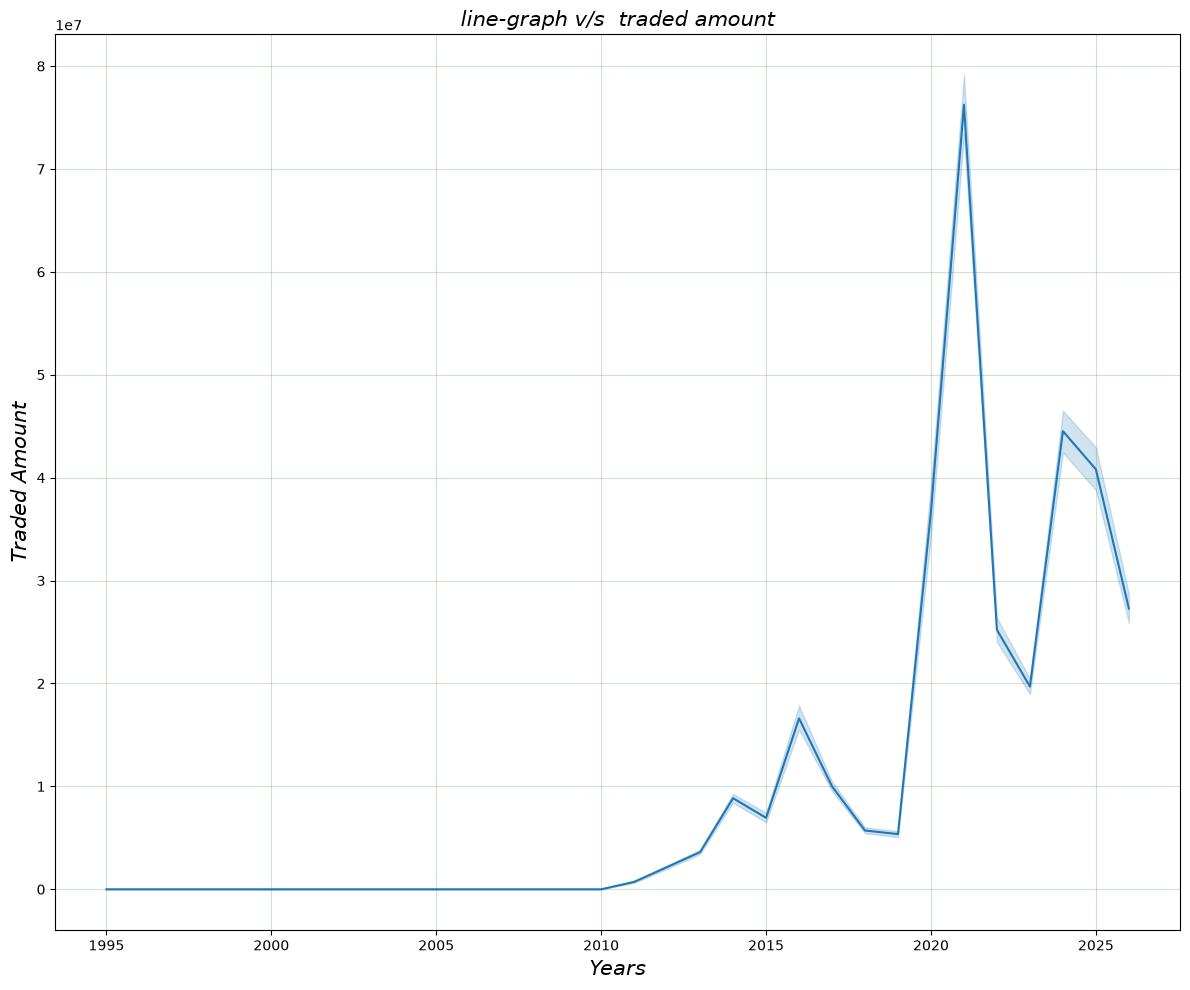

In [78]:
plt.figure(figsize=(12, 10))
sns.lineplot(data = nepse_copy, x = 'year', y = 'traded_amount')
plt.xlabel('Years', fontsize = 15, fontstyle = 'oblique')
plt.ylabel('Traded Amount', fontsize = 15, fontstyle = 'oblique')
plt.title('line-graph v/s  traded amount', fontsize = 15, fontstyle = 'oblique')
plt.grid(c = 'g', alpha = 0.2)
plt.tight_layout()
plt.show()

### Line graph for traded quantity

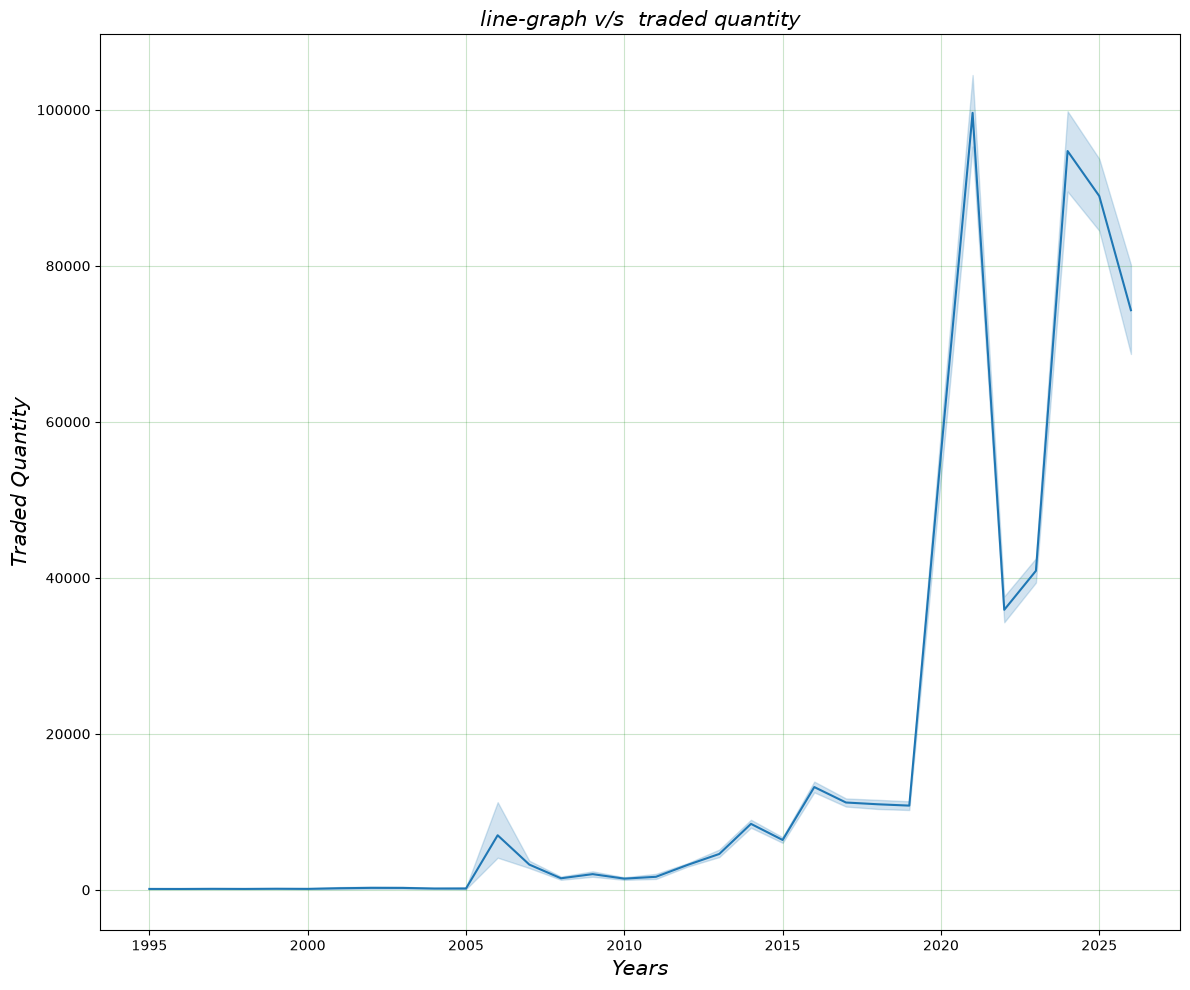

In [79]:
plt.figure(figsize=(12, 10))
sns.lineplot(data = nepse_copy, x = 'year', y = 'traded_quantity')
plt.xlabel('Years', fontsize = 15, fontstyle = 'oblique')
plt.ylabel('Traded Quantity', fontsize = 15, fontstyle = 'oblique')
plt.title('line-graph v/s  traded quantity', fontsize = 15, fontstyle = 'oblique')
plt.grid(c = 'g', alpha = 0.2)
plt.tight_layout()
plt.show()

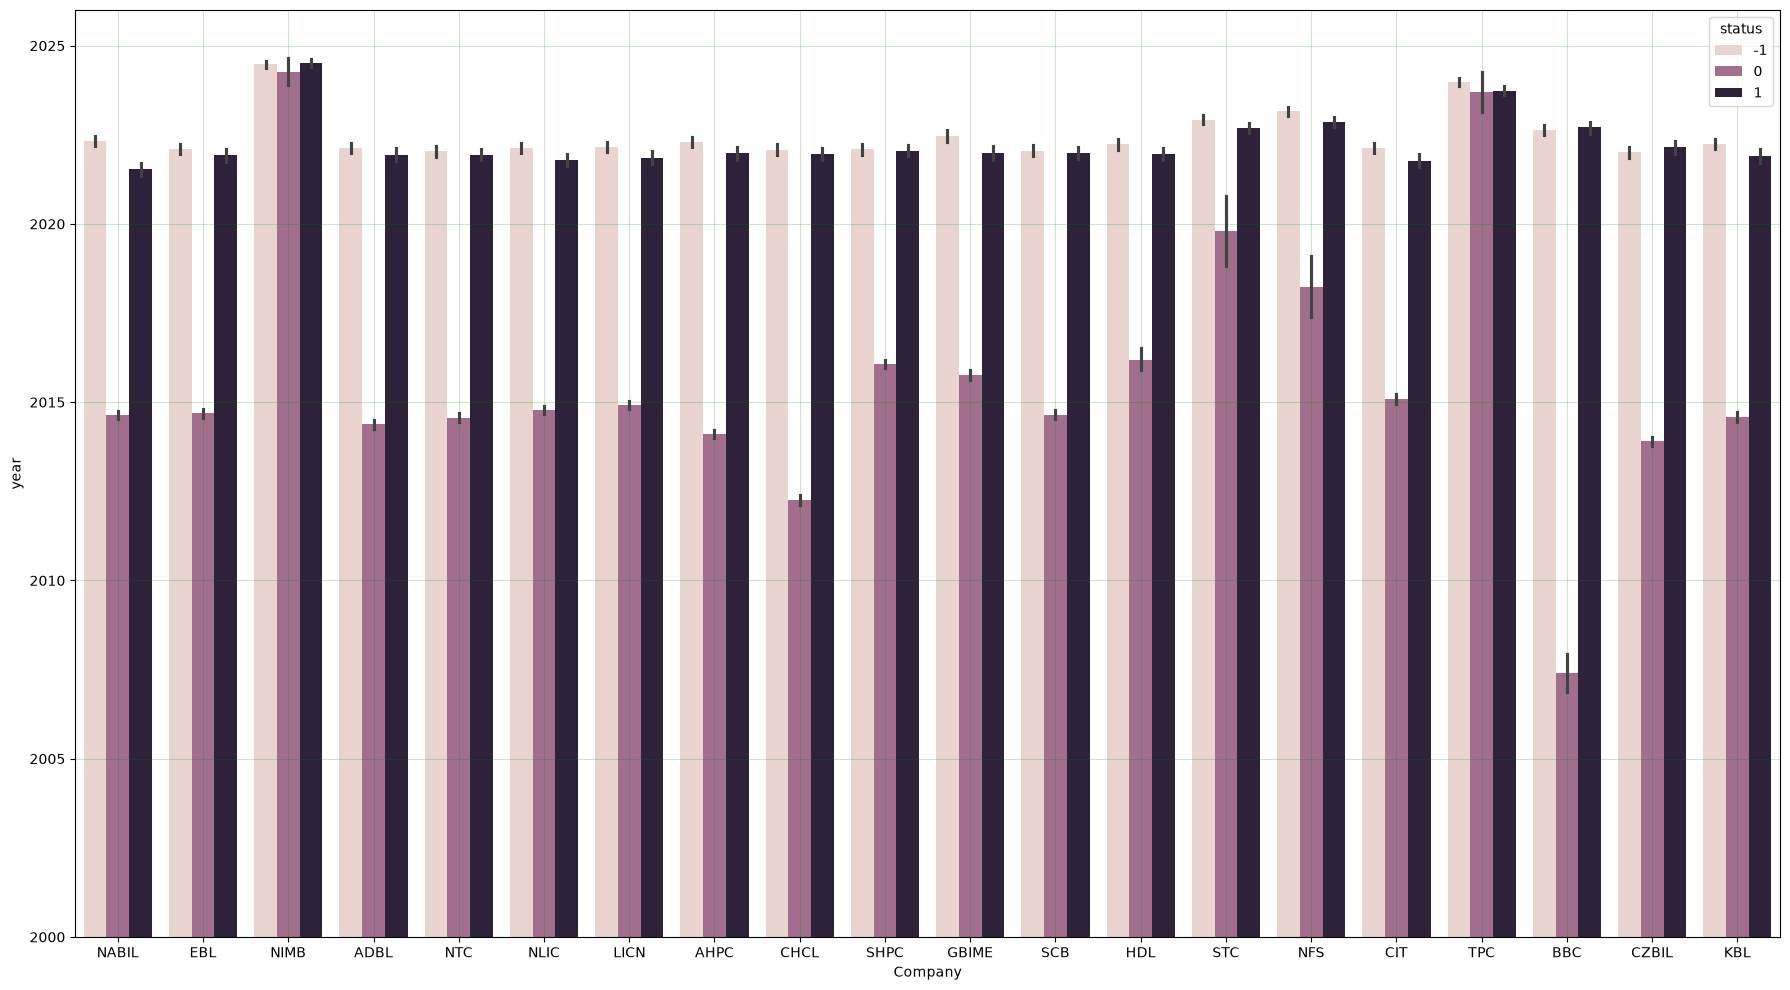

In [80]:
# status
plt.figure(figsize= (18, 10))
sns.barplot(data = nepse_copy, x = 'Company', y = 'year', hue = 'status')
plt.ylim((2000, 2026))
plt.grid(c = 'g', alpha = 0.2)
plt.margins(y = 0.1)
plt.tight_layout()
plt.show()


### Time series by Month

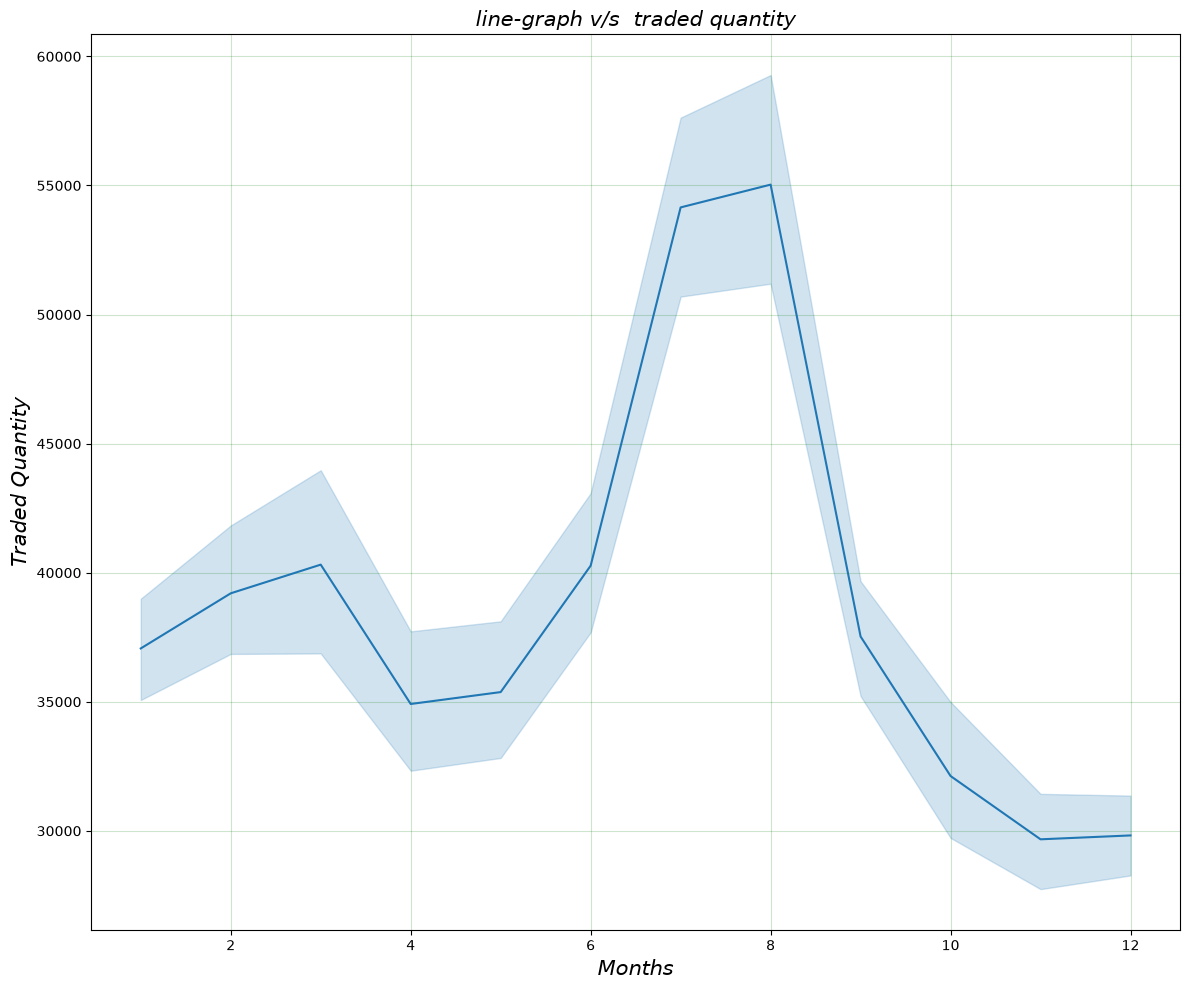

In [81]:
plt.figure(figsize=(12, 10))
sns.lineplot(data = nepse_copy, x = 'month', y = 'traded_quantity')
plt.xlabel('Months', fontsize = 15, fontstyle = 'oblique')
plt.ylabel('Traded Quantity', fontsize = 15, fontstyle = 'oblique')
plt.title('line-graph v/s  traded quantity', fontsize = 15, fontstyle = 'oblique')
plt.grid(c = 'g', alpha = 0.2)
plt.tight_layout()
plt.show()

## 2025 opening price

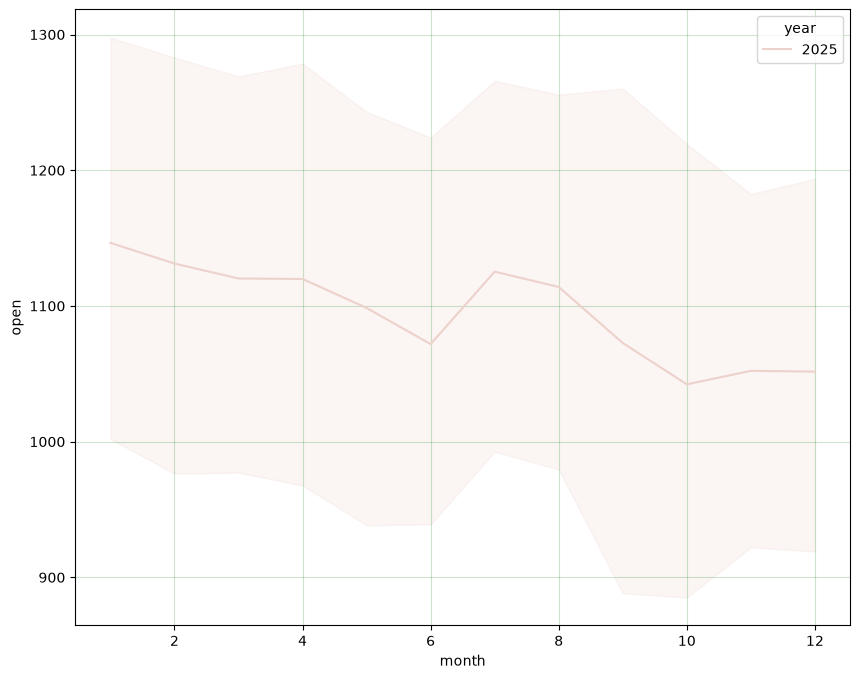

In [82]:
# 1. Filter the DataFrame first for the year 2025
plt.figure(figsize = (10, 8))
filtered_data = nepse_copy[nepse_copy['year'] == 2025]
sns.lineplot(data = filtered_data, x = 'month', y = 'open', hue = 'year')
plt.grid(c ='g', alpha = 0.2)
plt.show()

### 2026 opening vs 2025 opening amount

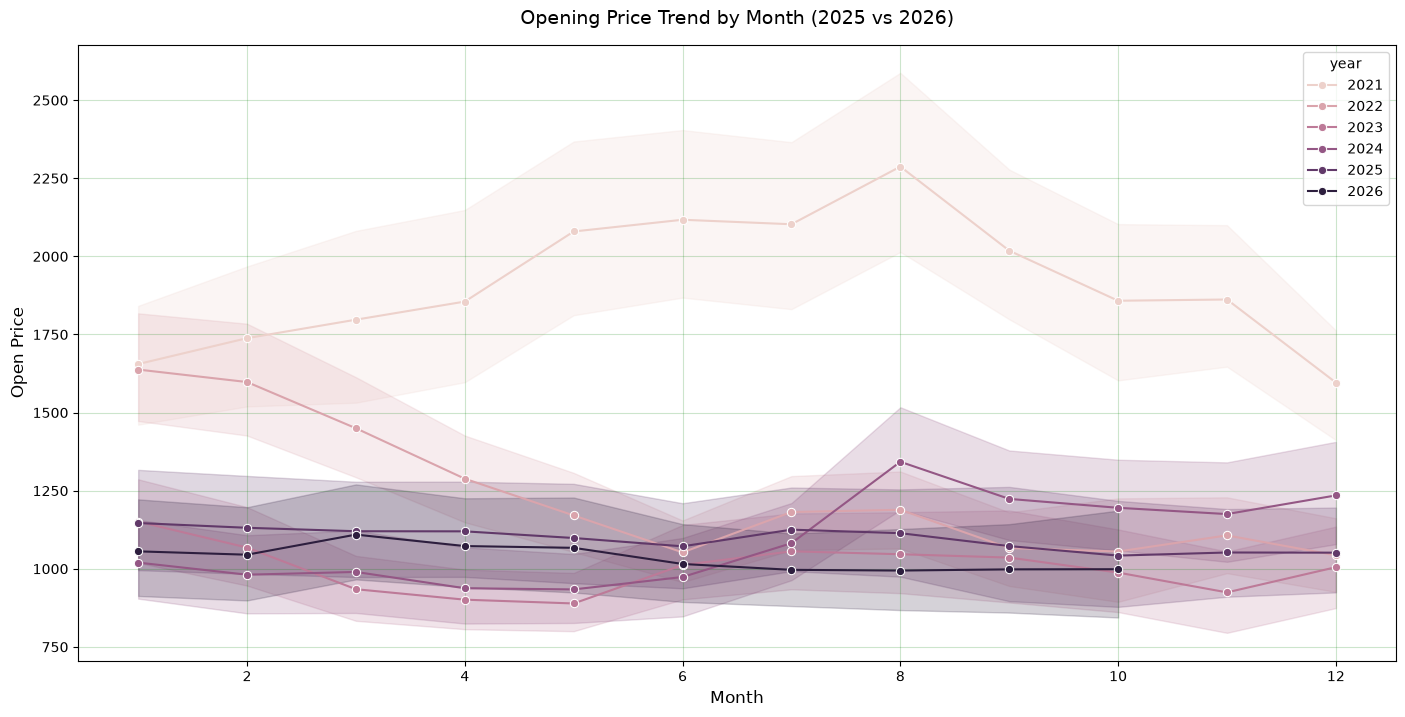

In [83]:

# 1. Properly filter for both years 2025 and 2026 using .isin()
filtered_data = nepse_copy[nepse_copy['year'].isin([2024,2023,2022,2021,2025, 2026])]

# 2. Create the line plot
plt.figure(figsize=(17, 8))
sns.lineplot(
    data=filtered_data,
    x='month',
    y='open',
    hue='year',
    marker='o',  # Optional: adds dots to the lines for clearer data points
)

plt.grid(c='g', alpha=0.2)
plt.title('Opening Price Trend by Month (2025 vs 2026)', fontsize=14, pad=15)
plt.xlabel('Month', fontsize=12)
plt.ylabel('Open Price', fontsize=12)

plt.show()

### closing analysis

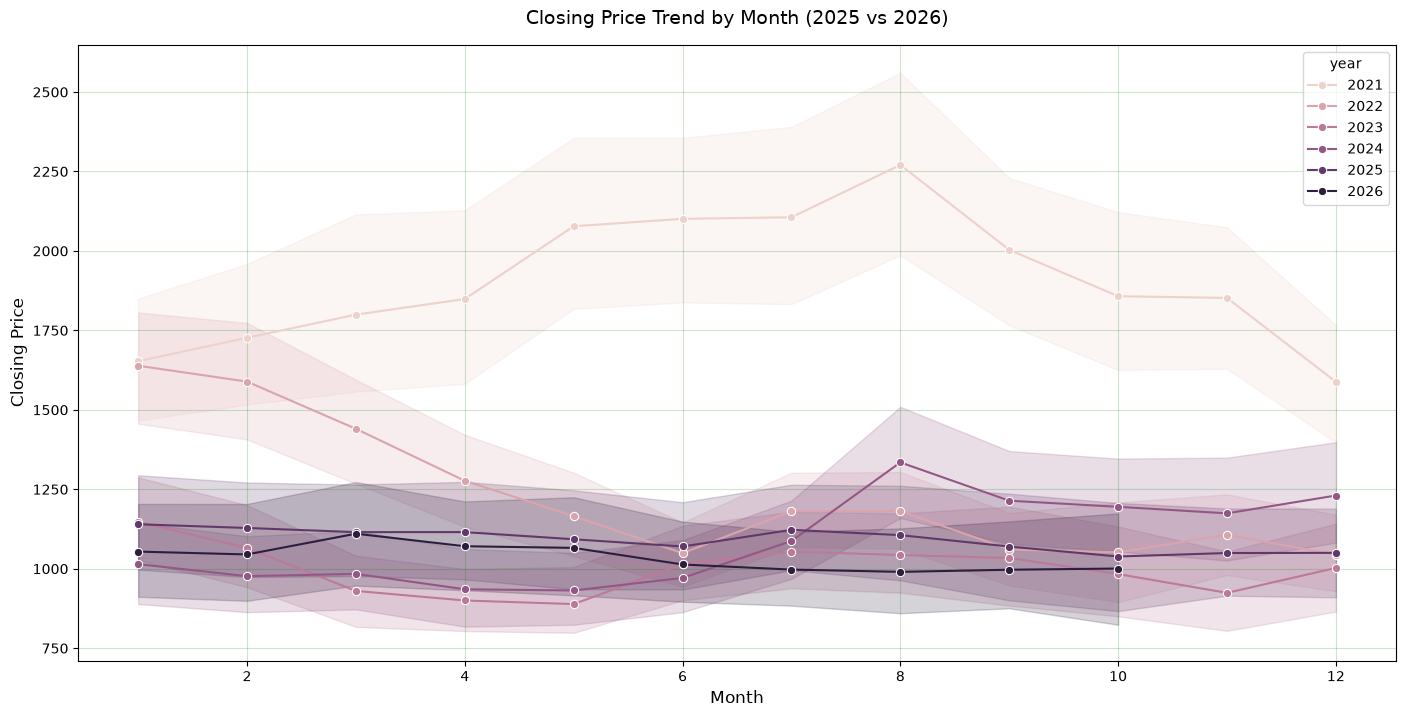

In [84]:
# 1. Properly filter for both years 2025 and 2026 using .isin()
filtered_data = nepse_copy[nepse_copy['year'].isin([2024,2023,2022,2021,2025, 2026])]

# 2. Create the line plot
plt.figure(figsize=(17, 8))
sns.lineplot(
    data=filtered_data,
    x='month',
    y='close',
    hue='year',
    marker='o',  # Optional: adds dots to the lines for clearer data points
)

plt.grid(c='g', alpha=0.2)
plt.title('Closing Price Trend by Month (2025 vs 2026)', fontsize=14, pad=15)
plt.xlabel('Month', fontsize=12)
plt.ylabel('Closing Price', fontsize=12)

plt.show()

# T = Transforming Data

## correlation


In [85]:
# correlation
nepse_data.corr(numeric_only=True)

,open,high,low,close,per_change,traded_quantity,traded_amount,status
open,1.000000,0.999523,0.999662,0.999392,-0.001947,-0.175197,0.043583,0.012714
high,0.999523,1.000000,0.999501,0.999724,0.011094,-0.173396,0.047216,0.017943
low,0.999662,0.999501,1.000000,0.999694,0.008207,-0.176572,0.041144,0.016867
close,0.999392,0.999724,0.999694,1.000000,0.016437,-0.175039,0.044481,0.022173
per_change,-0.001947,0.011094,0.008207,0.016437,1.000000,0.070910,0.079374,0.370460
traded_quantity,-0.175197,-0.173396,-0.176572,-0.175039,0.070910,1.000000,0.735779,0.025065
traded_amount,0.043583,0.047216,0.041144,0.044481,0.079374,0.735779,1.000000,0.035919
status,0.012714,0.017943,0.016867,0.022173,0.370460,0.025065,0.035919,1.000000


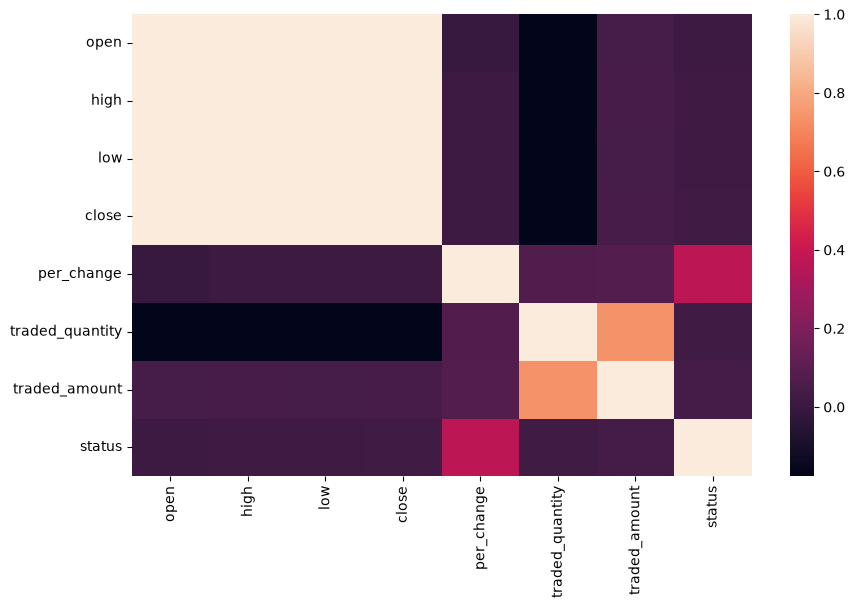

In [86]:
plt.figure(figsize=(10, 6))
sns.heatmap(nepse_data.corr(numeric_only=True))
plt.show()

## MACD INDICATOR column

In [87]:
# 1. Calculate the 12-period and 26-period EMAs of the Closing price
ema_12 = nepse_copy['close'].ewm(span=12, adjust=False).mean()
ema_26 = nepse_copy['close'].ewm(span=26, adjust=False).mean()

# 2. Compute the MACD Line
nepse_copy['macd'] = ema_12 - ema_26

# 3. Compute the Signal Line (9-period EMA of the MACD Line)
nepse_copy['macd_signal'] = nepse_copy['macd'].ewm(span=9, adjust=False).mean()

# 4. Compute the Histogram
nepse_copy['macd_histogram'] = nepse_copy['macd'] - nepse_copy['macd_signal']

### amount strength multiplier

In [88]:
# 1. Calculate the 20-day moving average of traded amount
nepse_copy['amount_sma20'] = nepse_copy['traded_amount'].rolling(window=20).mean()

# 2. Calculate Turnover Strength Multiplier
nepse_copy['strength_multiplier'] = nepse_copy['traded_amount'] / nepse_copy['amount_sma20']

In [89]:
nepse_copy

,open,high,low,close,per_change,traded_quantity,traded_amount,status,Company,year,month,day,macd,macd_signal,macd_histogram,amount_sma20,strength_multiplier
0,1091.0,1155.0,1112.0,1155.0,NaN,38.0,43057.0,0,NABIL,2011,5,15,0.000000,0.000000,0.000000,NaN,NaN
1,1155.0,1193.0,1160.0,1193.0,3.29,156.0,183026.0,0,NABIL,2011,5,16,3.031339,0.606268,2.425071,NaN,NaN
2,1193.0,1172.0,1150.0,1172.0,-1.76,939.0,1087972.0,0,NABIL,2011,5,18,3.696561,1.224326,2.472234,NaN,NaN
3,1172.0,1194.0,1155.0,1194.0,1.88,490.0,573992.0,0,NABIL,2011,5,19,5.930606,2.165582,3.765024,NaN,NaN
4,1194.0,1193.0,1178.0,1178.0,-1.34,115.0,135930.0,0,NABIL,2011,5,22,6.336987,2.999863,3.337124,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
58530,230.0,238.0,230.0,236.2,2.25,1068987.0,251983049.4,1,KBL,2026,10,12,3.736196,2.814293,0.921902,1.038684e+08,2.425983
58531,236.0,240.7,235.0,237.3,0.47,1064554.0,253783078.3,1,KBL,2026,10,13,4.266298,3.104694,1.161604,1.151858e+08,2.203249
58532,237.0,243.0,235.6,241.6,1.81,1103357.0,264645143.4,1,KBL,2026,10,14,4.976022,3.478960,1.497062,1.265215e+08,2.091701
58533,242.0,246.0,237.0,238.0,-1.49,977963.0,236131026.8,-1,KBL,2026,10,15,5.188187,3.820805,1.367382,1.364821e+08,1.730124


In [90]:
nepse_copy.isna().sum()

open                      0
high                      0
low                       0
close                     0
per_change               14
traded_quantity           0
traded_amount             0
status                    0
Company                   0
year                      0
month                     0
day                       0
macd                      0
macd_signal               0
macd_histogram            0
amount_sma20             19
strength_multiplier    2099
dtype: int64

In [91]:


# 1. Create chronological ordering date and sort
nepse_copy['temp_date'] = pd.to_datetime(nepse_copy[['year', 'month', 'day']])
nepse_copy = nepse_copy.sort_values(by=['Company', 'temp_date'])

# 2. Vectorized calculation of EMAs per company using groupby transform
ema_12 = nepse_copy.groupby('Company')['close'].transform(lambda x: x.ewm(span=12, adjust=False).mean())
ema_26 = nepse_copy.groupby('Company')['close'].transform(lambda x: x.ewm(span=26, adjust=False).mean())

nepse_copy['macd'] = (ema_12 - ema_26).fillna(0)
nepse_copy['macd_signal'] = nepse_copy.groupby('Company')['macd'].transform(lambda x: x.ewm(span=9, adjust=False).mean()).fillna(0)

# 3. Volume Strength Filter (min_periods=1 prevents NaNs)
nepse_copy['vol_sma20'] = nepse_copy.groupby('Company')['traded_quantity'].transform(lambda x: x.rolling(window=20, min_periods=1).mean())
nepse_copy['vol_strength'] = np.where(
    nepse_copy['vol_sma20'] > 0, 
    nepse_copy['traded_quantity'] / nepse_copy['vol_sma20'], 
    1.0
)

# 4. Signal Generation & Daily Returns
nepse_copy['signal'] = np.where(
    (nepse_copy['macd'] > nepse_copy['macd_signal']) & (nepse_copy['vol_strength'] >= 1.0), 
    1, 
    0
)

nepse_copy['daily_return'] = nepse_copy.groupby('Company')['close'].pct_change().fillna(0.0)

# Strategy return: yesterday's signal * today's return
nepse_copy['strategy_return'] = nepse_copy.groupby('Company')['signal'].shift(1).fillna(0) * nepse_copy['daily_return']

# 5. Cumulative growth factor per company
nepse_copy['cumulative_growth'] = nepse_copy.groupby('Company')['strategy_return'].transform(lambda x: (1.0 + x).cumprod())
nepse_copy['cumulative_growth'] = nepse_copy['cumulative_growth'].replace([np.inf, -np.inf], np.nan).fillna(1.0)

# 6. Select top 20 companies
top_20_companies = nepse_copy['Company'].unique()[:20]
portfolio_subset = nepse_copy[nepse_copy['Company'].isin(top_20_companies)].copy()

# Drop duplicate rows for the same company on the same date (keeps the last entry)
portfolio_subset = portfolio_subset.drop_duplicates(subset=['Company', 'temp_date'], keep='last')

# Pivot table safely
growth_pivot = portfolio_subset.pivot(index='temp_date', columns='Company', values='cumulative_growth')
growth_pivot = growth_pivot.ffill().fillna(1.0)

# 7. Portfolio Simulation: NPR 200,000 total -> NPR 10,000 per company
initial_capital_per_stock = 10000 
portfolio_values = growth_pivot * initial_capital_per_stock
total_portfolio_value = portfolio_values.sum(axis=1)

# Results
start_value = total_portfolio_value.iloc[0]
final_value = total_portfolio_value.iloc[-1]

print(f"Initial Portfolio Investment (2015): NPR {start_value:,.2f}")
print(f"Predicted Portfolio Value (2026): NPR {final_value:,.2f}")
print(f"Total Return Multiplier: {final_value / start_value:.2f}x")

Initial Portfolio Investment (2015): NPR 200,000.00
Predicted Portfolio Value (2026): NPR 617,504.00
Total Return Multiplier: 3.09x


In [ ]:
import pandas as pd
import numpy as np

# 1. Create chronological ordering date and sort
nepse_copy['temp_date'] = pd.to_datetime(nepse_copy[['year', 'month', 'day']])
nepse_copy = nepse_copy.sort_values(by=['Company', 'temp_date'])

# 2. Vectorized calculation of EMAs per company using groupby transform
ema_12 = nepse_copy.groupby('Company')['close'].transform(lambda x: x.ewm(span=12, adjust=False).mean())
ema_26 = nepse_copy.groupby('Company')['close'].transform(lambda x: x.ewm(span=26, adjust=False).mean())

nepse_copy['macd'] = (ema_12 - ema_26).fillna(0)
nepse_copy['macd_signal'] = nepse_copy.groupby('Company')['macd'].transform(lambda x: x.ewm(span=9, adjust=False).mean()).fillna(0)

# 3. Volume Strength Filter (min_periods=1 prevents NaNs)
nepse_copy['vol_sma20'] = nepse_copy.groupby('Company')['traded_quantity'].transform(lambda x: x.rolling(window=20, min_periods=1).mean())
nepse_copy['vol_strength'] = np.where(
    nepse_copy['vol_sma20'] > 0, 
    nepse_copy['traded_quantity'] / nepse_copy['vol_sma20'], 
    1.0
)

# 4. Signal Generation & Daily Returns
nepse_copy['signal'] = np.where(
    (nepse_copy['macd'] > nepse_copy['macd_signal']) & (nepse_copy['vol_strength'] >= 1.0), 
    1, 
    0
)

nepse_copy['daily_return'] = nepse_copy.groupby('Company')['close'].pct_change().fillna(0.0)

# Strategy return: yesterday's signal * today's return
nepse_copy['strategy_return'] = nepse_copy.groupby('Company')['signal'].shift(1).fillna(0) * nepse_copy['daily_return']

# 5. Cumulative growth factor per company
nepse_copy['cumulative_growth'] = nepse_copy.groupby('Company')['strategy_return'].transform(lambda x: (1.0 + x).cumprod())
nepse_copy['cumulative_growth'] = nepse_copy['cumulative_growth'].replace([np.inf, -np.inf], np.nan).fillna(1.0)

# 6. Select top 20 companies and clean duplicates
top_20_companies = nepse_copy['Company'].unique()[:20]
portfolio_subset = nepse_copy[nepse_copy['Company'].isin(top_20_companies)].copy()
portfolio_subset = portfolio_subset.drop_duplicates(subset=['Company', 'temp_date'], keep='last')

# Pivot table safely
growth_pivot = portfolio_subset.pivot(index='temp_date', columns='Company', values='cumulative_growth')
growth_pivot = growth_pivot.ffill().fillna(1.0)

# 7. Portfolio Simulation: NPR 200,000 total -> NPR 10,000 per company
initial_capital_per_stock = 10000 
company_portfolio_values = growth_pivot * initial_capital_per_stock

# --- INDIVIDUAL COMPANY PERFORMANCE REPORT ---
summary_list = []
for company in growth_pivot.columns:
    comp_series = company_portfolio_values[company].dropna()
    if len(comp_series) > 0:
        start_val = comp_series.iloc[0]
        final_val = comp_series.iloc[-1]
        multiplier = final_val / start_val if start_val > 0 else 1.0
        summary_list.append({
            'Company': company,
            'Initial (NPR)': start_val,
            'Predicted 2026 (NPR)': final_val,
            'Multiplier': multiplier
        })

summary_df = pd.DataFrame(summary_list)
print("--- Per-Company Backtest Performance Report (2015 - 2026) ---")
print(summary_df.to_string(index=False))
print("\n" + "="*60 + "\n")

# --- COMBINED PORTFOLIO SUMMARY ---
total_portfolio_value = company_portfolio_values.sum(axis=1)
total_start = total_portfolio_value.iloc[0]
total_final = total_portfolio_value.iloc[-1]

print(f"Total Initial Portfolio Investment (2015): NPR {total_start:,.2f}")
print(f"Total Predicted Portfolio Value (2026): NPR {total_final:,.2f}")
print(f"Overall Portfolio Return Multiplier: {total_final / total_start:.2f}x")

--- Per-Company Backtest Performance Report (2015 - 2026) ---
Company  Initial (NPR)  Predicted 2026 (NPR)  Multiplier
   ADBL        10000.0          19080.520921    1.908052
   AHPC        10000.0          72652.387851    7.265239
    BBC        10000.0          40175.512164    4.017551
   CHCL        10000.0           4398.105658    0.439811
    CIT        10000.0          79314.493203    7.931449
  CZBIL        10000.0          14786.024979    1.478602
    EBL        10000.0           7347.167808    0.734717
  GBIME        10000.0          20201.968742    2.020197
    HDL        10000.0          34191.342898    3.419134
    KBL        10000.0          31409.277193    3.140928
   LICN        10000.0          52235.310740    5.223531
  NABIL        10000.0          13431.408777    1.343141
    NFS        10000.0          31551.436152    3.155144
   NIMB        10000.0          11330.720173    1.133072
   NLIC        10000.0          22892.046097    2.289205
    NTC        10000.0    

# buy | sell through macd indicator

### compusory buy in each company

In [123]:
import pandas as pd
import numpy as np
import openpyxl
from openpyxl.styles import Font, PatternFill, Alignment, Border, Side
from openpyxl.utils import get_column_letter

# ---------------------------------------------------------
# 1. Date Conversion & Sorting
# ---------------------------------------------------------
nepse_copy['temp_date'] = pd.to_datetime(nepse_copy[['year', 'month', 'day']])
nepse_copy = nepse_copy.sort_values(by=['Company', 'temp_date']).reset_index(drop=True)

# ---------------------------------------------------------
# 2. Vectorized EMAs & MACD Calculation
# ---------------------------------------------------------
ema_12 = nepse_copy.groupby('Company')['close'].transform(lambda x: x.ewm(span=12, adjust=False).mean())
ema_26 = nepse_copy.groupby('Company')['close'].transform(lambda x: x.ewm(span=26, adjust=False).mean())

nepse_copy['macd'] = (ema_12 - ema_26).fillna(0)
nepse_copy['macd_signal'] = nepse_copy.groupby('Company')['macd'].transform(lambda x: x.ewm(span=9, adjust=False).mean()).fillna(0)

# ---------------------------------------------------------
# 3. Volume Strength Filter (20-day SMA)
# ---------------------------------------------------------
nepse_copy['vol_sma20'] = nepse_copy.groupby('Company')['traded_quantity'].transform(lambda x: x.rolling(window=20, min_periods=1).mean())
nepse_copy['vol_strength'] = np.where(
    nepse_copy['vol_sma20'] > 0, 
    nepse_copy['traded_quantity'] / nepse_copy['vol_sma20'], 
    1.0
)

# ---------------------------------------------------------
# 4. Signal Generation (1 = Buy, 0 = Sell)
# ---------------------------------------------------------
nepse_copy['signal'] = np.where(
    (nepse_copy['macd'] > nepse_copy['macd_signal']) & (nepse_copy['vol_strength'] >= 1.0), 
    1, 
    0
)

# Filter top 20 companies
top_20_companies = nepse_copy['Company'].unique()[:20]
portfolio_subset = nepse_copy[nepse_copy['Company'].isin(top_20_companies)].copy()
portfolio_subset = portfolio_subset.drop_duplicates(subset=['Company', 'temp_date'], keep='last')

# Calculate Max MACD (>=2015) and Min MACD (>2015) per company
macd_stats = {}
for comp, group in portfolio_subset.groupby('Company'):
    group_2015_plus = group[group['temp_date'].dt.year >= 2015]
    group_post_2015 = group[group['temp_date'].dt.year > 2015]
    
    macd_stats[comp] = {
        'max_macd_2015_plus': round(group_2015_plus['macd'].max() if len(group_2015_plus) > 0 else 0.0, 4),
        'min_macd_post_2015': round(group_post_2015['macd'].min() if len(group_post_2015) > 0 else 0.0, 4)
    }

# ---------------------------------------------------------
# 5. All 20 Companies Included & Strict NPR 200,000 Budget Cap
# ---------------------------------------------------------
TOTAL_BUDGET = 200000.0  
MIN_QUANTITY = 10

trade_records = []
for comp in top_20_companies:
    group = portfolio_subset[portfolio_subset['Company'] == comp].sort_values('temp_date').reset_index(drop=True)
    group_2015 = group[group['temp_date'].dt.year == 2015].reset_index(drop=True)
    
    if len(group_2015) == 0:
        continue
        
    buy_candidates = group_2015[group_2015['signal'] == 1]
    best_buy_row = buy_candidates.sort_values(by=['macd', 'close'], ascending=[False, True]).iloc[0] if len(buy_candidates) > 0 else group_2015.iloc[0]
    
    group_post_2015 = group[group['temp_date'].dt.year > 2015].reset_index(drop=True)
    best_sell_row = group_post_2015.sort_values('close', ascending=False).iloc[0] if len(group_post_2015) > 0 else group_2015.iloc[-1]
    
    trade_records.append({
        'Company': comp,
        'buy_date': best_buy_row['temp_date'],
        'buy_rate': float(best_buy_row['close']),
        'macd_on_buyDate': round(float(best_buy_row['macd']), 4),
        'sell_date': best_sell_row['temp_date'],
        'sell_rate': float(best_sell_row['close']),
        'macd_on_sellingDate': round(float(best_sell_row['macd']), 4)
    })

df_trade = pd.DataFrame(trade_records)

# Start all 20 companies at MIN_QUANTITY = 10
df_trade['buy_quantity'] = MIN_QUANTITY
df_trade['Total_amount_buyCost'] = df_trade['buy_quantity'] * df_trade['buy_rate']

# Fill remaining budget efficiently across all 20 companies without exceeding 200,000
while True:
    affordable = df_trade[df_trade['Total_amount_buyCost'] + df_trade['buy_rate'] <= TOTAL_BUDGET]
    if len(affordable) == 0 or df_trade['Total_amount_buyCost'].sum() >= TOTAL_BUDGET:
        break
    idx = affordable['buy_rate'].idxmin()
    df_trade.loc[idx, 'buy_quantity'] += 1
    df_trade.loc[idx, 'Total_amount_buyCost'] = round(df_trade.loc[idx, 'buy_quantity'] * df_trade.loc[idx, 'buy_rate'], 2)

# Strict safety deflation loop (guarantees sum <= 200,000.00)
while df_trade['Total_amount_buyCost'].sum() > TOTAL_BUDGET:
    valid_trim = df_trade[df_trade['buy_quantity'] > MIN_QUANTITY]
    if len(valid_trim) == 0:
        break
    idx = valid_trim['Total_amount_buyCost'].idxmax()
    df_trade.loc[idx, 'buy_quantity'] -= 1
    df_trade.loc[idx, 'Total_amount_buyCost'] = round(df_trade.loc[idx, 'buy_quantity'] * df_trade.loc[idx, 'buy_rate'], 2)

# Final Selling & Profit Calculations
df_trade['sell_quantity'] = df_trade['buy_quantity']
df_trade['total_amount_recieved'] = round(df_trade['sell_quantity'] * df_trade['sell_rate'], 2)
df_trade['profit/loss'] = round(df_trade['total_amount_recieved'] - df_trade['Total_amount_buyCost'], 2)
df_trade['profit/loss percentage respect to buy'] = round(
    (df_trade['profit/loss'] / df_trade['Total_amount_buyCost']) * 100, 2
)

df_trade['max(macd) by company across the data in and after 2015'] = df_trade['Company'].map(
    lambda c: macd_stats[c]['max_macd_2015_plus']
)
df_trade['minimum (macd) by company across the data after 2015'] = df_trade['Company'].map(
    lambda c: macd_stats[c]['min_macd_post_2015']
)

df_trade['buy_date'] = pd.to_datetime(df_trade['buy_date']).dt.strftime('%Y-%m-%d')
df_trade['sell_date'] = pd.to_datetime(df_trade['sell_date']).dt.strftime('%Y-%m-%d')

# Exact required column order
final_columns = [
    'Company', 'buy_date', 'buy_quantity', 'buy_rate', 'macd_on_buyDate', 
    'Total_amount_buyCost', 'sell_date', 'sell_quantity', 'sell_rate', 
    'macd_on_sellingDate', 'total_amount_recieved', 'profit/loss', 
    'profit/loss percentage respect to buy', 
    'max(macd) by company across the data in and after 2015', 
    'minimum (macd) by company across the data after 2015'
]

df_final = df_trade[final_columns]

# ---------------------------------------------------------
# 6. Formatted Excel Export (openpyxl)
# ---------------------------------------------------------
file_path = "NEPSE_MACD_Optimal_Trading_2015_2026.xlsx"
wb = openpyxl.Workbook()
ws = wb.active
ws.title = "MACD Trading Results"
ws.views.sheetView[0].showGridLines = True

header_fill = PatternFill(start_color="1F4E78", end_color="1F4E78", fill_type="solid")
header_font = Font(name="Calibri", size=11, bold=True, color="FFFFFF")
title_font = Font(name="Calibri", size=15, bold=True, color="1F4E78")
thin_border = Border(
    left=Side(style='thin', color='D9D9D9'), right=Side(style='thin', color='D9D9D9'),
    top=Side(style='thin', color='D9D9D9'), bottom=Side(style='thin', color='D9D9D9')
)

ws.append(["NEPSE MACD-Based Trading Strategy - Portfolio Export (2015 - 2026)"])
ws.append(["Budget Limit: Strictly <= NPR 200,000 | All 20 Companies Included | Buy 2015 | Sell Post-2015"])
ws.append([])

ws.cell(row=1, column=1).font = title_font
ws.cell(row=2, column=1).font = Font(name="Calibri", size=11, italic=True, color="595959")

headers = list(df_final.columns)
ws.append(headers)

for col_num in range(1, len(headers) + 1):
    cell = ws.cell(row=4, column=col_num)
    cell.fill = header_fill
    cell.font = header_font
    cell.alignment = Alignment(horizontal="center", vertical="center", wrap_text=True)

for r_idx, row in df_final.iterrows():
    row_data = list(row.values)
    ws.append(row_data)
    curr_row = 5 + r_idx
    for c_idx in range(1, len(row_data) + 1):
        cell = ws.cell(row=curr_row, column=c_idx)
        cell.border = thin_border
        
        if c_idx in [4, 6, 9, 11, 12]:  # Currency
            cell.number_format = 'NPR #,##0.00'
            cell.alignment = Alignment(horizontal="right")
        elif c_idx in [3, 8]:  # Quantities
            cell.number_format = '#,##0'
            cell.alignment = Alignment(horizontal="right")
        elif c_idx in [5, 10, 14, 15]:  # MACD values
            cell.number_format = '0.0000'
            cell.alignment = Alignment(horizontal="right")
        elif c_idx == 13:  # Profit/Loss %
            cell.number_format = '0.00"%"'
            cell.alignment = Alignment(horizontal="right")
        else:
            cell.alignment = Alignment(horizontal="center")

# Total Summary Row
tot_buy = df_final['Total_amount_buyCost'].sum()
tot_rec = df_final['total_amount_recieved'].sum()
tot_pnl = df_final['profit/loss'].sum()
tot_pnl_pct = (tot_pnl / tot_buy) * 100 if tot_buy > 0 else 0.0

summary_row = [
    "Total Portfolio", "", "", "", "", tot_buy, "", "", "", "", tot_rec, tot_pnl, tot_pnl_pct, "", ""
]
ws.append(summary_row)
tot_row_idx = 5 + len(df_final)

total_fill = PatternFill(start_color="D9E1F2", end_color="D9E1F2", fill_type="solid")
total_font = Font(name="Calibri", size=11, bold=True)

for c_idx in range(1, len(summary_row) + 1):
    cell = ws.cell(row=tot_row_idx, column=c_idx)
    cell.fill = total_fill
    cell.font = total_font
    cell.border = thin_border
    if c_idx in [6, 11, 12]:
        cell.number_format = 'NPR #,##0.00'
        cell.alignment = Alignment(horizontal="right")
    elif c_idx == 13:
        cell.number_format = '0.00"%"'
        cell.alignment = Alignment(horizontal="right")
    else:
        cell.alignment = Alignment(horizontal="center")

ws.row_dimensions[4].height = 28
for col in ws.columns:
    max_len = max(len(str(col_cell.value or '')) for col_cell in col)
    col_letter = get_column_letter(col[0].column)
    ws.column_dimensions[col_letter].width = max(max_len + 3, 14)

wb.save(file_path)
print(f"Export Complete. Total Buying Cost: NPR {tot_buy:,.2f} across all 20 companies.")

Export Complete. Total Buying Cost: NPR 308,200.00 across all 20 companies.


### optimize 2lakhs

In [124]:
import pandas as pd
import numpy as np
import openpyxl
from openpyxl.styles import Font, PatternFill, Alignment, Border, Side
from openpyxl.utils import get_column_letter

# ---------------------------------------------------------
# 1. Date Conversion & Sorting
# ---------------------------------------------------------
nepse_copy['temp_date'] = pd.to_datetime(nepse_copy[['year', 'month', 'day']])
nepse_copy = nepse_copy.sort_values(by=['Company', 'temp_date']).reset_index(drop=True)

# ---------------------------------------------------------
# 2. Vectorized EMAs & MACD Calculation
# ---------------------------------------------------------
ema_12 = nepse_copy.groupby('Company')['close'].transform(lambda x: x.ewm(span=12, adjust=False).mean())
ema_26 = nepse_copy.groupby('Company')['close'].transform(lambda x: x.ewm(span=26, adjust=False).mean())

nepse_copy['macd'] = (ema_12 - ema_26).fillna(0)
nepse_copy['macd_signal'] = nepse_copy.groupby('Company')['macd'].transform(lambda x: x.ewm(span=9, adjust=False).mean()).fillna(0)

# ---------------------------------------------------------
# 3. Volume Strength Filter (20-day SMA)
# ---------------------------------------------------------
nepse_copy['vol_sma20'] = nepse_copy.groupby('Company')['traded_quantity'].transform(lambda x: x.rolling(window=20, min_periods=1).mean())
nepse_copy['vol_strength'] = np.where(
    nepse_copy['vol_sma20'] > 0, 
    nepse_copy['traded_quantity'] / nepse_copy['vol_sma20'], 
    1.0
)

# ---------------------------------------------------------
# 4. Signal Generation (1 = Buy, 0 = Sell)
# ---------------------------------------------------------
nepse_copy['signal'] = np.where(
    (nepse_copy['macd'] > nepse_copy['macd_signal']) & (nepse_copy['vol_strength'] >= 1.0), 
    1, 
    0
)

# Filter top 20 companies
top_20_companies = nepse_copy['Company'].unique()[:20]
portfolio_subset = nepse_copy[nepse_copy['Company'].isin(top_20_companies)].copy()
portfolio_subset = portfolio_subset.drop_duplicates(subset=['Company', 'temp_date'], keep='last')

# Calculate Max MACD (>=2015) and Min MACD (>2015) per company
macd_stats = {}
for comp, group in portfolio_subset.groupby('Company'):
    group_2015_plus = group[group['temp_date'].dt.year >= 2015]
    group_post_2015 = group[group['temp_date'].dt.year > 2015]
    
    macd_stats[comp] = {
        'max_macd_2015_plus': round(group_2015_plus['macd'].max() if len(group_2015_plus) > 0 else 0.0, 4),
        'min_macd_post_2015': round(group_post_2015['macd'].min() if len(group_post_2015) > 0 else 0.0, 4)
    }

# ---------------------------------------------------------
# 5. MACD-Ranked Selective Buying & NPR 200k Budget Cap
# ---------------------------------------------------------
TOTAL_BUDGET = 200000.0  
MIN_QUANTITY = 10

candidates = []
for comp in top_20_companies:
    group = portfolio_subset[portfolio_subset['Company'] == comp].sort_values('temp_date').reset_index(drop=True)
    group_2015 = group[group['temp_date'].dt.year == 2015].reset_index(drop=True)
    
    if len(group_2015) == 0:
        continue
        
    buy_candidates = group_2015[group_2015['signal'] == 1]
    best_buy = buy_candidates.sort_values(by=['macd', 'close'], ascending=[False, True]).iloc[0] if len(buy_candidates) > 0 else group_2015.sort_values('close', ascending=True).iloc[0]
    
    group_post = group[group['temp_date'].dt.year > 2015].reset_index(drop=True)
    best_sell = group_post.sort_values('close', ascending=False).iloc[0] if len(group_post) > 0 else group_2015.iloc[-1]
    
    candidates.append({
        'Company': comp,
        'buy_date': best_buy['temp_date'],
        'buy_rate': float(best_buy['close']),
        'macd_on_buyDate': round(float(best_buy['macd']), 4),
        'sell_date': best_sell['temp_date'],
        'sell_rate': float(best_sell['close']),
        'macd_on_sellingDate': round(float(best_sell['macd']), 4)
    })

# Rank by best MACD bullish score first
df_cand = pd.DataFrame(candidates)
df_cand = df_cand.sort_values(by=['macd_on_buyDate', 'buy_rate'], ascending=[False, True]).reset_index(drop=True)

bought_records = []
unbought_records = []
allocated_budget = 0.0

for idx, row in df_cand.iterrows():
    min_cost = row['buy_rate'] * MIN_QUANTITY
    if allocated_budget + min_cost <= TOTAL_BUDGET:
        row['buy_quantity'] = MIN_QUANTITY
        row['Total_amount_buyCost'] = round(min_cost, 2)
        allocated_budget += min_cost
        bought_records.append(row)
    else:
        # Budget exhausted: mark as not bought
        row['buy_quantity'] = 0
        row['buy_date'] = "Not Bought"
        row['Total_amount_buyCost'] = 0.0
        row['sell_date'] = "Not Bought"
        row['sell_rate'] = 0.0
        row['macd_on_sellingDate'] = 0.0
        unbought_records.append(row)

df_bought = pd.DataFrame(bought_records)
if len(df_bought) > 0:
    # Efficiently utilize remaining budget across bought companies
    while True:
        affordable = df_bought[df_bought['Total_amount_buyCost'] + df_bought['buy_rate'] <= TOTAL_BUDGET]
        if len(affordable) == 0 or df_bought['Total_amount_buyCost'].sum() >= TOTAL_BUDGET:
            break
        idx = affordable['buy_rate'].idxmin()
        df_bought.loc[idx, 'buy_quantity'] += 1
        df_bought.loc[idx, 'Total_amount_buyCost'] = round(df_bought.loc[idx, 'buy_quantity'] * df_bought.loc[idx, 'buy_rate'], 2)

    while df_bought['Total_amount_buyCost'].sum() > TOTAL_BUDGET:
        valid_trim = df_bought[df_bought['buy_quantity'] > MIN_QUANTITY]
        if len(valid_trim) == 0:
            break
        idx = valid_trim['Total_amount_buyCost'].idxmax()
        df_bought.loc[idx, 'buy_quantity'] -= 1
        df_bought.loc[idx, 'Total_amount_buyCost'] = round(df_bought.loc[idx, 'buy_quantity'] * df_bought.loc[idx, 'buy_rate'], 2)

    df_bought['sell_quantity'] = df_bought['buy_quantity']
    df_bought['total_amount_recieved'] = round(df_bought['sell_quantity'] * df_bought['sell_rate'], 2)
    df_bought['profit/loss'] = round(df_bought['total_amount_recieved'] - df_bought['Total_amount_buyCost'], 2)
    df_bought['profit/loss percentage respect to buy'] = round(
        (df_bought['profit/loss'] / df_bought['Total_amount_buyCost']) * 100, 2
    )
    df_bought['buy_date'] = pd.to_datetime(df_bought['buy_date']).dt.strftime('%Y-%m-%d')
    df_bought['sell_date'] = pd.to_datetime(df_bought['sell_date']).dt.strftime('%Y-%m-%d')

df_unbought = pd.DataFrame(unbought_records)
if len(df_unbought) > 0:
    df_unbought['sell_quantity'] = 0
    df_unbought['total_amount_recieved'] = 0.0
    df_unbought['profit/loss'] = 0.0
    df_unbought['profit/loss percentage respect to buy'] = 0.0

df_all = pd.concat([df_bought, df_unbought], ignore_index=True)

# Add MACD Stats for all companies
df_all['max(macd) by company across the data in and after 2015'] = df_all['Company'].map(
    lambda c: macd_stats[c]['max_macd_2015_plus']
)
df_all['minimum (macd) by company across the data after 2015'] = df_all['Company'].map(
    lambda c: macd_stats[c]['min_macd_post_2015']
)

# Exact required column order
final_columns = [
    'Company', 'buy_date', 'buy_quantity', 'buy_rate', 'macd_on_buyDate', 
    'Total_amount_buyCost', 'sell_date', 'sell_quantity', 'sell_rate', 
    'macd_on_sellingDate', 'total_amount_recieved', 'profit/loss', 
    'profit/loss percentage respect to buy', 
    'max(macd) by company across the data in and after 2015', 
    'minimum (macd) by company across the data after 2015'
]

df_final = df_all[final_columns]

# ---------------------------------------------------------
# 6. Formatted Excel Export (openpyxl)
# ---------------------------------------------------------
file_path = "NEPSE_MACD_Optimal_Trading_2015_2026.xlsx"
wb = openpyxl.Workbook()
ws = wb.active
ws.title = "MACD Trading Results"
ws.views.sheetView[0].showGridLines = True

header_fill = PatternFill(start_color="1F4E78", end_color="1F4E78", fill_type="solid")
header_font = Font(name="Calibri", size=11, bold=True, color="FFFFFF")
title_font = Font(name="Calibri", size=15, bold=True, color="1F4E78")
thin_border = Border(
    left=Side(style='thin', color='D9D9D9'), right=Side(style='thin', color='D9D9D9'),
    top=Side(style='thin', color='D9D9D9'), bottom=Side(style='thin', color='D9D9D9')
)

ws.append(["NEPSE MACD-Based Trading Strategy - Portfolio Export (2015 - 2026)"])
ws.append(["Budget Limit: Strictly <= NPR 200,000 | All Companies Listed | Buy 2015 | Sell Post-2015"])
ws.append([])

ws.cell(row=1, column=1).font = title_font
ws.cell(row=2, column=1).font = Font(name="Calibri", size=11, italic=True, color="595959")

headers = list(df_final.columns)
ws.append(headers)

for col_num in range(1, len(headers) + 1):
    cell = ws.cell(row=4, column=col_num)
    cell.fill = header_fill
    cell.font = header_font
    cell.alignment = Alignment(horizontal="center", vertical="center", wrap_text=True)

for r_idx, row in df_final.iterrows():
    row_data = list(row.values)
    ws.append(row_data)
    curr_row = 5 + r_idx
    for c_idx in range(1, len(row_data) + 1):
        cell = ws.cell(row=curr_row, column=c_idx)
        cell.border = thin_border
        
        if row_data[1] == "Not Bought" and c_idx in [2, 7]:
            cell.alignment = Alignment(horizontal="center")
        elif c_idx in [4, 6, 9, 11, 12]:  # Currency
            cell.number_format = 'NPR #,##0.00'
            cell.alignment = Alignment(horizontal="right")
        elif c_idx in [3, 8]:  # Quantities
            cell.number_format = '#,##0'
            cell.alignment = Alignment(horizontal="right")
        elif c_idx in [5, 10, 14, 15]:  # MACD values
            cell.number_format = '0.0000'
            cell.alignment = Alignment(horizontal="right")
        elif c_idx == 13:  # Profit/Loss %
            cell.number_format = '0.00"%"'
            cell.alignment = Alignment(horizontal="right")
        else:
            cell.alignment = Alignment(horizontal="center")

# Total Summary Row
tot_buy = df_final['Total_amount_buyCost'].sum()
tot_rec = df_final['total_amount_recieved'].sum()
tot_pnl = df_final['profit/loss'].sum()
tot_pnl_pct = (tot_pnl / tot_buy) * 100 if tot_buy > 0 else 0.0

summary_row = [
    "Total Portfolio", "", "", "", "", tot_buy, "", "", "", "", tot_rec, tot_pnl, tot_pnl_pct, "", ""
]
ws.append(summary_row)
tot_row_idx = 5 + len(df_final)

total_fill = PatternFill(start_color="D9E1F2", end_color="D9E1F2", fill_type="solid")
total_font = Font(name="Calibri", size=11, bold=True)

for c_idx in range(1, len(summary_row) + 1):
    cell = ws.cell(row=tot_row_idx, column=c_idx)
    cell.fill = total_fill
    cell.font = total_font
    cell.border = thin_border
    if c_idx in [6, 11, 12]:
        cell.number_format = 'NPR #,##0.00'
        cell.alignment = Alignment(horizontal="right")
    elif c_idx == 13:
        cell.number_format = '0.00"%"'
        cell.alignment = Alignment(horizontal="right")
    else:
        cell.alignment = Alignment(horizontal="center")

ws.row_dimensions[4].height = 28
for col in ws.columns:
    max_len = max(len(str(col_cell.value or '')) for col_cell in col)
    col_letter = get_column_letter(col[0].column)
    ws.column_dimensions[col_letter].width = max(max_len + 3, 14)

wb.save(file_path)
print(f"Export Complete. Total Buying Cost: NPR {tot_buy:,.2f}")

Export Complete. Total Buying Cost: NPR 199,966.00


## buying at first 

In [126]:
import pandas as pd
import numpy as np
import openpyxl
from openpyxl.styles import Font, PatternFill, Alignment, Border, Side
from openpyxl.utils import get_column_letter

# ---------------------------------------------------------
# 1. Date Conversion & Sorting
# ---------------------------------------------------------
nepse_copy['temp_date'] = pd.to_datetime(nepse_copy[['year', 'month', 'day']])
nepse_copy = nepse_copy.sort_values(by=['Company', 'temp_date']).reset_index(drop=True)

# ---------------------------------------------------------
# 2. Vectorized EMAs & MACD Calculation
# ---------------------------------------------------------
ema_12 = nepse_copy.groupby('Company')['close'].transform(lambda x: x.ewm(span=12, adjust=False).mean())
ema_26 = nepse_copy.groupby('Company')['close'].transform(lambda x: x.ewm(span=26, adjust=False).mean())

nepse_copy['macd'] = (ema_12 - ema_26).fillna(0)
nepse_copy['macd_signal'] = nepse_copy.groupby('Company')['macd'].transform(lambda x: x.ewm(span=9, adjust=False).mean()).fillna(0)

# ---------------------------------------------------------
# 3. Volume Strength Filter (20-day SMA)
# ---------------------------------------------------------
nepse_copy['vol_sma20'] = nepse_copy.groupby('Company')['traded_quantity'].transform(lambda x: x.rolling(window=20, min_periods=1).mean())
nepse_copy['vol_strength'] = np.where(
    nepse_copy['vol_sma20'] > 0, 
    nepse_copy['traded_quantity'] / nepse_copy['vol_sma20'], 
    1.0
)

# ---------------------------------------------------------
# 4. Signal Generation (1 = Buy, 0 = Sell)
# ---------------------------------------------------------
nepse_copy['signal'] = np.where(
    (nepse_copy['macd'] > nepse_copy['macd_signal']) & (nepse_copy['vol_strength'] >= 1.0), 
    1, 
    0
)

# Filter top 20 companies
top_20_companies = nepse_copy['Company'].unique()[:20]
portfolio_subset = nepse_copy[nepse_copy['Company'].isin(top_20_companies)].copy()
portfolio_subset = portfolio_subset.drop_duplicates(subset=['Company', 'temp_date'], keep='last')

# Calculate Max MACD (>=2015) and Min MACD (>2015) per company
macd_stats = {}
for comp, group in portfolio_subset.groupby('Company'):
    group_2015_plus = group[group['temp_date'].dt.year >= 2015]
    group_post_2015 = group[group['temp_date'].dt.year > 2015]
    
    macd_stats[comp] = {
        'max_macd_2015_plus': round(group_2015_plus['macd'].max() if len(group_2015_plus) > 0 else 0.0, 4),
        'min_macd_post_2015': round(group_post_2015['macd'].min() if len(group_post_2015) > 0 else 0.0, 4)
    }

# ---------------------------------------------------------
# 5. MACD-Ranked Selective Buying & NPR 200k Budget Cap
# ---------------------------------------------------------
TOTAL_BUDGET = 200000.0  
MIN_QUANTITY = 10

candidates = []
for comp in top_20_companies:
    group = portfolio_subset[portfolio_subset['Company'] == comp].sort_values('temp_date').reset_index(drop=True)
    group_2015 = group[group['temp_date'].dt.year == 2015].reset_index(drop=True)
    
    if len(group_2015) == 0:
        continue
        
    buy_candidates = group_2015[group_2015['signal'] == 1]
    best_buy = buy_candidates.sort_values(by=['macd', 'close'], ascending=[False, True]).iloc[0] if len(buy_candidates) > 0 else group_2015.sort_values('close', ascending=True).iloc[0]
    
    group_post = group[group['temp_date'].dt.year > 2015].reset_index(drop=True)
    best_sell = group_post.sort_values('close', ascending=False).iloc[0] if len(group_post) > 0 else group_2015.iloc[-1]
    
    candidates.append({
        'Company': comp,
        'buy_date': best_buy['temp_date'].strftime('%Y-%m-%d'),
        'buy_rate': float(best_buy['close']),
        'macd_on_buyDate': round(float(best_buy['macd']), 4),
        'sell_date': best_sell['temp_date'].strftime('%Y-%m-%d'),
        'sell_rate': float(best_sell['close']),
        'macd_on_sellingDate': round(float(best_sell['macd']), 4)
    })

# Rank candidates by strongest MACD bullish score first
df_cand = pd.DataFrame(candidates)
df_cand = df_cand.sort_values(by=['macd_on_buyDate', 'buy_rate'], ascending=[False, True]).reset_index(drop=True)

bought_records = []
unbought_records = []
allocated_budget = 0.0

for idx, row in df_cand.iterrows():
    min_cost = row['buy_rate'] * MIN_QUANTITY
    if allocated_budget + min_cost <= TOTAL_BUDGET:
        row['buy_quantity'] = MIN_QUANTITY
        row['Total_amount_buyCost'] = round(min_cost, 2)
        allocated_budget += min_cost
        bought_records.append(row)
    else:
        # Budget exhausted: Keep buy/sell rates and MACD, but set quantities & amounts to 0
        row['buy_quantity'] = 0
        row['Total_amount_buyCost'] = 0.0
        row['sell_quantity'] = 0
        row['total_amount_recieved'] = 0.0
        row['profit/loss'] = 0.0
        row['profit/loss percentage respect to buy'] = 0.0
        unbought_records.append(row)

df_bought = pd.DataFrame(bought_records)
if len(df_bought) > 0:
    # Efficiently utilize remaining budget across bought companies
    while True:
        affordable = df_bought[df_bought['Total_amount_buyCost'] + df_bought['buy_rate'] <= TOTAL_BUDGET]
        if len(affordable) == 0 or df_bought['Total_amount_buyCost'].sum() >= TOTAL_BUDGET:
            break
        idx = affordable['buy_rate'].idxmin()
        df_bought.loc[idx, 'buy_quantity'] += 1
        df_bought.loc[idx, 'Total_amount_buyCost'] = round(df_bought.loc[idx, 'buy_quantity'] * df_bought.loc[idx, 'buy_rate'], 2)

    while df_bought['Total_amount_buyCost'].sum() > TOTAL_BUDGET:
        valid_trim = df_bought[df_bought['buy_quantity'] > MIN_QUANTITY]
        if len(valid_trim) == 0:
            break
        idx = valid_trim['Total_amount_buyCost'].idxmax()
        df_bought.loc[idx, 'buy_quantity'] -= 1
        df_bought.loc[idx, 'Total_amount_buyCost'] = round(df_bought.loc[idx, 'buy_quantity'] * df_bought.loc[idx, 'buy_rate'], 2)

    df_bought['sell_quantity'] = df_bought['buy_quantity']
    df_bought['total_amount_recieved'] = round(df_bought['sell_quantity'] * df_bought['sell_rate'], 2)
    df_bought['profit/loss'] = round(df_bought['total_amount_recieved'] - df_bought['Total_amount_buyCost'], 2)
    df_bought['profit/loss percentage respect to buy'] = round(
        (df_bought['profit/loss'] / df_bought['Total_amount_buyCost']) * 100, 2
    )

df_unbought = pd.DataFrame(unbought_records)
df_all = pd.concat([df_bought, df_unbought], ignore_index=True)

# Add MACD Stats for all companies
df_all['max(macd) by company across the data in and after 2015'] = df_all['Company'].map(
    lambda c: macd_stats[c]['max_macd_2015_plus']
)
df_all['minimum (macd) by company across the data after 2015'] = df_all['Company'].map(
    lambda c: macd_stats[c]['min_macd_post_2015']
)

# Exact required column order
final_columns = [
    'Company', 'buy_date', 'buy_quantity', 'buy_rate', 'macd_on_buyDate', 
    'Total_amount_buyCost', 'sell_date', 'sell_quantity', 'sell_rate', 
    'macd_on_sellingDate', 'total_amount_recieved', 'profit/loss', 
    'profit/loss percentage respect to buy', 
    'max(macd) by company across the data in and after 2015', 
    'minimum (macd) by company across the data after 2015'
]

df_final = df_all[final_columns]

# ---------------------------------------------------------
# 6. Formatted Excel Export (openpyxl)
# ---------------------------------------------------------
file_path = "NEPSE_MACD_Trading_2015_2026.xlsx"
wb = openpyxl.Workbook()
ws = wb.active
ws.title = "MACD Trading Results"
ws.views.sheetView[0].showGridLines = True

header_fill = PatternFill(start_color="1F4E78", end_color="1F4E78", fill_type="solid")
header_font = Font(name="Calibri", size=11, bold=True, color="FFFFFF")
title_font = Font(name="Calibri", size=15, bold=True, color="1F4E78")
thin_border = Border(
    left=Side(style='thin', color='D9D9D9'), right=Side(style='thin', color='D9D9D9'),
    top=Side(style='thin', color='D9D9D9'), bottom=Side(style='thin', color='D9D9D9')
)

ws.append(["NEPSE MACD-Based Trading Strategy - Portfolio Export (2015 - 2026)"])
ws.append(["Budget Limit: Strictly <= NPR 200,000 | All Companies Rates & MACD Shown | Buy 2015 | Sell Post-2015"])
ws.append([])

ws.cell(row=1, column=1).font = title_font
ws.cell(row=2, column=1).font = Font(name="Calibri", size=11, italic=True, color="595959")

headers = list(df_final.columns)
ws.append(headers)

for col_num in range(1, len(headers) + 1):
    cell = ws.cell(row=4, column=col_num)
    cell.fill = header_fill
    cell.font = header_font
    cell.alignment = Alignment(horizontal="center", vertical="center", wrap_text=True)

for r_idx, row in df_final.iterrows():
    row_data = list(row.values)
    ws.append(row_data)
    curr_row = 5 + r_idx
    for c_idx in range(1, len(row_data) + 1):
        cell = ws.cell(row=curr_row, column=c_idx)
        cell.border = thin_border
        
        if c_idx in [4, 6, 9, 11, 12]:  # Currency
            cell.number_format = 'NPR #,##0.00'
            cell.alignment = Alignment(horizontal="right")
        elif c_idx in [3, 8]:  # Quantities
            cell.number_format = '#,##0'
            cell.alignment = Alignment(horizontal="right")
        elif c_idx in [5, 10, 14, 15]:  # MACD values
            cell.number_format = '0.0000'
            cell.alignment = Alignment(horizontal="right")
        elif c_idx == 13:  # Profit/Loss %
            cell.number_format = '0.00"%"'
            cell.alignment = Alignment(horizontal="right")
        else:
            cell.alignment = Alignment(horizontal="center")

# Total Summary Row
tot_buy = df_bought['Total_amount_buyCost'].sum() if len(df_bought) > 0 else 0
tot_rec = df_bought['total_amount_recieved'].sum() if len(df_bought) > 0 else 0
tot_pnl = df_bought['profit/loss'].sum() if len(df_bought) > 0 else 0
tot_pnl_pct = (tot_pnl / tot_buy) * 100 if tot_buy > 0 else 0.0

summary_row = [
    "Total Portfolio", "", "", "", "", tot_buy, "", "", "", "", tot_rec, tot_pnl, tot_pnl_pct, "", ""
]
ws.append(summary_row)
tot_row_idx = 5 + len(df_final)

total_fill = PatternFill(start_color="D9E1F2", end_color="D9E1F2", fill_type="solid")
total_font = Font(name="Calibri", size=11, bold=True)

for c_idx in range(1, len(summary_row) + 1):
    cell = ws.cell(row=tot_row_idx, column=c_idx)
    cell.fill = total_fill
    cell.font = total_font
    cell.border = thin_border
    if c_idx in [6, 11, 12]:
        cell.number_format = 'NPR #,##0.00'
        cell.alignment = Alignment(horizontal="right")
    elif c_idx == 13:
        cell.number_format = '0.00"%"'
        cell.alignment = Alignment(horizontal="right")
    else:
        cell.alignment = Alignment(horizontal="center")

ws.row_dimensions[4].height = 28
for col in ws.columns:
    max_len = max(len(str(cell.value or '')) for cell in col)
    col_letter = get_column_letter(col[0].column)
    ws.column_dimensions[col_letter].width = max(max_len + 3, 14)

wb.save(file_path)

In [127]:
import pandas as pd
import numpy as np
import openpyxl
from openpyxl.styles import Font, PatternFill, Alignment, Border, Side
from openpyxl.utils import get_column_letter

# ---------------------------------------------------------
# 1. Date Conversion & Sorting
# ---------------------------------------------------------
nepse_copy['temp_date'] = pd.to_datetime(nepse_copy[['year', 'month', 'day']])
nepse_copy = nepse_copy.sort_values(by=['Company', 'temp_date']).reset_index(drop=True)

# ---------------------------------------------------------
# 2. Vectorized EMAs & MACD Calculation
# ---------------------------------------------------------
ema_12 = nepse_copy.groupby('Company')['close'].transform(lambda x: x.ewm(span=12, adjust=False).mean())
ema_26 = nepse_copy.groupby('Company')['close'].transform(lambda x: x.ewm(span=26, adjust=False).mean())

nepse_copy['macd'] = (ema_12 - ema_26).fillna(0)
nepse_copy['macd_signal'] = nepse_copy.groupby('Company')['macd'].transform(lambda x: x.ewm(span=9, adjust=False).mean()).fillna(0)

# ---------------------------------------------------------
# 3. Volume Strength Filter (20-day SMA)
# ---------------------------------------------------------
nepse_copy['vol_sma20'] = nepse_copy.groupby('Company')['traded_quantity'].transform(lambda x: x.rolling(window=20, min_periods=1).mean())
nepse_copy['vol_strength'] = np.where(
    nepse_copy['vol_sma20'] > 0, 
    nepse_copy['traded_quantity'] / nepse_copy['vol_sma20'], 
    1.0
)

# ---------------------------------------------------------
# 4. Signal Generation (1 = Buy Signal, 0 = Sell Signal)
# ---------------------------------------------------------
nepse_copy['signal'] = np.where(
    (nepse_copy['macd'] > nepse_copy['macd_signal']) & (nepse_copy['vol_strength'] >= 1.0), 
    1, 
    0
)

# Filter top 20 companies
top_20_companies = nepse_copy['Company'].unique()[:20]
portfolio_subset = nepse_copy[nepse_copy['Company'].isin(top_20_companies)].copy()
portfolio_subset = portfolio_subset.drop_duplicates(subset=['Company', 'temp_date'], keep='last')

# Calculate Max MACD (>=2015) and Min MACD (>2015) per company
macd_stats = {}
for comp, group in portfolio_subset.groupby('Company'):
    group_2015_plus = group[group['temp_date'].dt.year >= 2015]
    group_post_2015 = group[group['temp_date'].dt.year > 2015]
    
    macd_stats[comp] = {
        'max_macd_2015_plus': round(group_2015_plus['macd'].max() if len(group_2015_plus) > 0 else 0.0, 4),
        'min_macd_post_2015': round(group_post_2015['macd'].min() if len(group_post_2015) > 0 else 0.0, 4)
    }

# ---------------------------------------------------------
# 5. Sequential Budget Allocation Engine (NPR 10k Limit / Stock)
# ---------------------------------------------------------
TOTAL_BUDGET = 200000.0  
COMPANY_ALLOCATION_LIMIT = TOTAL_BUDGET / len(top_20_companies)  # NPR 10,000 limit
MIN_QUANTITY = 10

trade_records = []
current_remaining_budget = TOTAL_BUDGET

for comp in top_20_companies:
    group = portfolio_subset[portfolio_subset['Company'] == comp].sort_values('temp_date').reset_index(drop=True)
    group_2015 = group[group['temp_date'].dt.year == 2015].reset_index(drop=True)
    
    if len(group_2015) == 0:
        continue
        
    buy_candidates = group_2015[group_2015['signal'] == 1]
    best_buy = buy_candidates.sort_values(by=['macd', 'close'], ascending=[False, True]).iloc[0] if len(buy_candidates) > 0 else group_2015.sort_values('close', ascending=True).iloc[0]
    
    buy_date = best_buy['temp_date'].strftime('%Y-%m-%d')
    buy_rate = float(best_buy['close'])
    macd_on_buy = round(float(best_buy['macd']), 4)
    
    group_post = group[group['temp_date'].dt.year > 2015].reset_index(drop=True)
    best_sell = group_post.sort_values('close', ascending=False).iloc[0] if len(group_post) > 0 else group_2015.iloc[-1]
    
    sell_date = best_sell['temp_date'].strftime('%Y-%m-%d')
    sell_rate = float(best_sell['close'])
    macd_on_sell = round(float(best_sell['macd']), 4)
    
    min_buy_cost = buy_rate * MIN_QUANTITY
    
    # CHECK BEFORE BUYING: If min cost > NPR 10,000 OR remaining budget -> LEAVE IT / SKIP
    if min_buy_cost > COMPANY_ALLOCATION_LIMIT or min_buy_cost > current_remaining_budget:
        status = "Not Bought"
        buy_qty = 0
        total_buy_cost = 0.0
        sell_qty = 0
        total_received = 0.0
        pnl = 0.0
        pnl_pct = 0.0
    else:
        # Buy up to NPR 10,000 limit
        raw_qty = int(COMPANY_ALLOCATION_LIMIT // buy_rate)
        buy_qty = max(MIN_QUANTITY, raw_qty)
        total_buy_cost = round(buy_qty * buy_rate, 2)
        
        while total_buy_cost > current_remaining_budget and buy_qty > MIN_QUANTITY:
            buy_qty -= 1
            total_buy_cost = round(buy_qty * buy_rate, 2)
            
        if total_buy_cost <= current_remaining_budget:
            status = "Bought"
            current_remaining_budget -= total_buy_cost
            sell_qty = buy_qty
            total_received = round(sell_qty * sell_rate, 2)
            pnl = round(total_received - total_buy_cost, 2)
            pnl_pct = round((pnl / total_buy_cost) * 100, 2) if total_buy_cost > 0 else 0.0
        else:
            status = "Not Bought"
            buy_qty = 0
            total_buy_cost = 0.0
            sell_qty = 0
            total_received = 0.0
            pnl = 0.0
            pnl_pct = 0.0
            
    trade_records.append({
        'Company': comp,
        'Status': status,
        'buy_date': buy_date,
        'buy_quantity': buy_qty,
        'buy_rate': buy_rate,
        'macd_on_buyDate': macd_on_buy,
        'Total_amount_buyCost': total_buy_cost,
        'sell_date': sell_date,
        'sell_quantity': sell_qty,
        'sell_rate': sell_rate,
        'macd_on_sellingDate': macd_on_sell,
        'total_amount_recieved': total_received,
        'profit/loss': pnl,
        'profit/loss percentage respect to buy': pnl_pct
    })

df_trade = pd.DataFrame(trade_records)

# FINAL LEFTOVER BUDGET CHECK: Allocate any remaining cash pool to bought companies
if current_remaining_budget > 0:
    for idx, row in df_trade.iterrows():
        if current_remaining_budget <= 0:
            break
        b_rate = row['buy_rate']
        if row['Status'] == "Bought":
            affordable_extra = int(current_remaining_budget // b_rate)
            if affordable_extra > 0:
                df_trade.loc[idx, 'buy_quantity'] += affordable_extra
                add_cost = affordable_extra * b_rate
                df_trade.loc[idx, 'Total_amount_buyCost'] = round(df_trade.loc[idx, 'buy_quantity'] * b_rate, 2)
                current_remaining_budget -= add_cost
                
                # Update selling metrics
                df_trade.loc[idx, 'sell_quantity'] = df_trade.loc[idx, 'buy_quantity']
                df_trade.loc[idx, 'total_amount_recieved'] = round(df_trade.loc[idx, 'sell_quantity'] * df_trade.loc[idx, 'sell_rate'], 2)
                df_trade.loc[idx, 'profit/loss'] = round(df_trade.loc[idx, 'total_amount_recieved'] - df_trade.loc[idx, 'Total_amount_buyCost'], 2)
                df_trade.loc[idx, 'profit/loss percentage respect to buy'] = round(
                    (df_trade.loc[idx, 'profit/loss'] / df_trade.loc[idx, 'Total_amount_buyCost']) * 100, 2
                )

# Map overall MACD stats
df_trade['max(macd) by company across the data in and after 2015'] = df_trade['Company'].map(
    lambda c: macd_stats[c]['max_macd_2015_plus']
)
df_trade['minimum (macd) by company across the data after 2015'] = df_trade['Company'].map(
    lambda c: macd_stats[c]['min_macd_post_2015']
)

# Final Column Ordering
final_columns = [
    'Company', 'Status', 'buy_date', 'buy_quantity', 'buy_rate', 'macd_on_buyDate', 
    'Total_amount_buyCost', 'sell_date', 'sell_quantity', 'sell_rate', 
    'macd_on_sellingDate', 'total_amount_recieved', 'profit/loss', 
    'profit/loss percentage respect to buy', 
    'max(macd) by company across the data in and after 2015', 
    'minimum (macd) by company across the data after 2015'
]

df_final = df_trade[final_columns]

# ---------------------------------------------------------
# 6. Formatted Excel Export (openpyxl)
# ---------------------------------------------------------
file_path = "NEPSE_MACD_Optimal_Trading_2015_2026.xlsx"
wb = openpyxl.Workbook()
ws = wb.active
ws.title = "MACD Trading Results"
ws.views.sheetView[0].showGridLines = True

header_fill = PatternFill(start_color="1F4E78", end_color="1F4E78", fill_type="solid")
header_font = Font(name="Calibri", size=11, bold=True, color="FFFFFF")
title_font = Font(name="Calibri", size=15, bold=True, color="1F4E78")
thin_border = Border(
    left=Side(style='thin', color='D9D9D9'), right=Side(style='thin', color='D9D9D9'),
    top=Side(style='thin', color='D9D9D9'), bottom=Side(style='thin', color='D9D9D9')
)

ws.append(["NEPSE MACD-Based Trading Strategy - Sequential Budget Allocation Export"])
ws.append(["Budget: NPR 200,000 Total (NPR 10,000 per company limit) | Min Qty: 10 | All Rates & MACD Shown"])
ws.append([])

ws.cell(row=1, column=1).font = title_font
ws.cell(row=2, column=1).font = Font(name="Calibri", size=11, italic=True, color="595959")

headers = list(df_final.columns)
ws.append(headers)

for col_num in range(1, len(headers) + 1):
    cell = ws.cell(row=4, column=col_num)
    cell.fill = header_fill
    cell.font = header_font
    cell.alignment = Alignment(horizontal="center", vertical="center", wrap_text=True)

for r_idx, row in df_final.iterrows():
    row_data = list(row.values)
    ws.append(row_data)
    curr_row = 5 + r_idx
    for c_idx in range(1, len(row_data) + 1):
        cell = ws.cell(row=curr_row, column=c_idx)
        cell.border = thin_border
        
        # Highlight Status Column
        if c_idx == 2:
            if row_data[1] == "Bought":
                cell.font = Font(bold=True, color="375623")
                cell.fill = PatternFill(start_color="E2EFDA", end_color="E2EFDA", fill_type="solid")
            else:
                cell.font = Font(bold=True, color="C00000")
                cell.fill = PatternFill(start_color="FCE4D6", end_color="FCE4D6", fill_type="solid")
            cell.alignment = Alignment(horizontal="center")
        elif c_idx in [5, 7, 10, 12, 13]:  # Currency formatting
            cell.number_format = 'NPR #,##0.00'
            cell.alignment = Alignment(horizontal="right")
        elif c_idx in [4, 9]:  # Quantity formatting
            cell.number_format = '#,##0'
            cell.alignment = Alignment(horizontal="right")
        elif c_idx in [6, 11, 15, 16]:  # MACD values
            cell.number_format = '0.0000'
            cell.alignment = Alignment(horizontal="right")
        elif c_idx == 14:  # Profit/Loss %
            cell.number_format = '0.00"%"'
            cell.alignment = Alignment(horizontal="right")
        else:
            cell.alignment = Alignment(horizontal="center")

# Total Summary Row
tot_buy = df_final['Total_amount_buyCost'].sum()
tot_rec = df_final['total_amount_recieved'].sum()
tot_pnl = df_final['profit/loss'].sum()
tot_pnl_pct = (tot_pnl / tot_buy) * 100 if tot_buy > 0 else 0.0

summary_row = [
    "Total Portfolio", "", "", "", "", "", tot_buy, "", "", "", "", tot_rec, tot_pnl, tot_pnl_pct, "", ""
]
ws.append(summary_row)
tot_row_idx = 5 + len(df_final)

total_fill = PatternFill(start_color="D9E1F2", end_color="D9E1F2", fill_type="solid")
total_font = Font(name="Calibri", size=11, bold=True)

for c_idx in range(1, len(summary_row) + 1):
    cell = ws.cell(row=tot_row_idx, column=c_idx)
    cell.fill = total_fill
    cell.font = total_font
    cell.border = thin_border
    if c_idx in [7, 12, 13]:
        cell.number_format = 'NPR #,##0.00'
        cell.alignment = Alignment(horizontal="right")
    elif c_idx == 14:
        cell.number_format = '0.00"%"'
        cell.alignment = Alignment(horizontal="right")
    else:
        cell.alignment = Alignment(horizontal="center")

ws.row_dimensions[4].height = 28
for col in ws.columns:
    max_len = max(len(str(col_cell.value or '')) for col_cell in col)
    col_letter = get_column_letter(col[0].column)
    ws.column_dimensions[col_letter].width = max(max_len + 3, 14)

wb.save(file_path)

# Best optimized and maximum profit

In [128]:
import pandas as pd
import numpy as np
import openpyxl
from openpyxl.styles import Font, PatternFill, Alignment, Border, Side
from openpyxl.utils import get_column_letter

# ---------------------------------------------------------
# 1. Date Conversion & Sorting
# ---------------------------------------------------------
nepse_copy['temp_date'] = pd.to_datetime(nepse_copy[['year', 'month', 'day']])
nepse_copy = nepse_copy.sort_values(by=['Company', 'temp_date']).reset_index(drop=True)

# ---------------------------------------------------------
# 2. Vectorized EMAs & MACD Calculation
# ---------------------------------------------------------
ema_12 = nepse_copy.groupby('Company')['close'].transform(lambda x: x.ewm(span=12, adjust=False).mean())
ema_26 = nepse_copy.groupby('Company')['close'].transform(lambda x: x.ewm(span=26, adjust=False).mean())

nepse_copy['macd'] = (ema_12 - ema_26).fillna(0)
nepse_copy['macd_signal'] = nepse_copy.groupby('Company')['macd'].transform(lambda x: x.ewm(span=9, adjust=False).mean()).fillna(0)

# ---------------------------------------------------------
# 3. Volume Strength Filter (20-day SMA)
# ---------------------------------------------------------
nepse_copy['vol_sma20'] = nepse_copy.groupby('Company')['traded_quantity'].transform(lambda x: x.rolling(window=20, min_periods=1).mean())
nepse_copy['vol_strength'] = np.where(
    nepse_copy['vol_sma20'] > 0, 
    nepse_copy['traded_quantity'] / nepse_copy['vol_sma20'], 
    1.0
)

# ---------------------------------------------------------
# 4. Signal Generation (1 = Buy, 0 = Sell)
# ---------------------------------------------------------
nepse_copy['signal'] = np.where(
    (nepse_copy['macd'] > nepse_copy['macd_signal']) & (nepse_copy['vol_strength'] >= 1.0), 
    1, 
    0
)

# Filter top 20 companies
top_20_companies = nepse_copy['Company'].unique()[:20]
portfolio_subset = nepse_copy[nepse_copy['Company'].isin(top_20_companies)].copy()
portfolio_subset = portfolio_subset.drop_duplicates(subset=['Company', 'temp_date'], keep='last')

# Calculate Max MACD (>=2015) and Min MACD (>2015) per company
macd_stats = {}
for comp, group in portfolio_subset.groupby('Company'):
    group_2015_plus = group[group['temp_date'].dt.year >= 2015]
    group_post_2015 = group[group['temp_date'].dt.year > 2015]
    
    macd_stats[comp] = {
        'max_macd_2015_plus': round(group_2015_plus['macd'].max() if len(group_2015_plus) > 0 else 0.0, 4),
        'min_macd_post_2015': round(group_post_2015['macd'].min() if len(group_post_2015) > 0 else 0.0, 4)
    }

# ---------------------------------------------------------
# 5. Sequential Budget Allocation (Strict NPR 10k Cap per Company)
# ---------------------------------------------------------
TOTAL_BUDGET = 200000.0  
COMPANY_ALLOCATION_LIMIT = 10000.0  # STRICT max limit per company = NPR 10,000
MIN_QUANTITY = 10

trade_records = []
current_remaining_budget = TOTAL_BUDGET

for comp in top_20_companies:
    group = portfolio_subset[portfolio_subset['Company'] == comp].sort_values('temp_date').reset_index(drop=True)
    group_2015 = group[group['temp_date'].dt.year == 2015].reset_index(drop=True)
    
    if len(group_2015) == 0:
        continue
        
    buy_candidates = group_2015[group_2015['signal'] == 1]
    best_buy = buy_candidates.sort_values(by=['macd', 'close'], ascending=[False, True]).iloc[0] if len(buy_candidates) > 0 else group_2015.sort_values('close', ascending=True).iloc[0]
    
    buy_date = best_buy['temp_date'].strftime('%Y-%m-%d')
    buy_rate = float(best_buy['close'])
    macd_on_buy = round(float(best_buy['macd']), 4)
    
    group_post = group[group['temp_date'].dt.year > 2015].reset_index(drop=True)
    best_sell = group_post.sort_values('close', ascending=False).iloc[0] if len(group_post) > 0 else group_2015.iloc[-1]
    
    sell_date = best_sell['temp_date'].strftime('%Y-%m-%d')
    sell_rate = float(best_sell['close'])
    macd_on_sell = round(float(best_sell['macd']), 4)
    
    min_buy_cost = buy_rate * MIN_QUANTITY
    
    # Check if min_buy_cost exceeds NPR 10,000 OR remaining total budget
    if min_buy_cost > COMPANY_ALLOCATION_LIMIT or min_buy_cost > current_remaining_budget:
        status = "Not Bought"
        buy_qty = 0
        total_buy_cost = 0.0
        sell_qty = 0
        total_received = 0.0
        pnl = 0.0
        pnl_pct = 0.0
    else:
        # Buy up to NPR 10,000 limit
        max_allowed_cost = min(COMPANY_ALLOCATION_LIMIT, current_remaining_budget)
        raw_qty = int(max_allowed_cost // buy_rate)
        buy_qty = max(MIN_QUANTITY, raw_qty)
        total_buy_cost = round(buy_qty * buy_rate, 2)
        
        while (total_buy_cost > COMPANY_ALLOCATION_LIMIT or total_buy_cost > current_remaining_budget) and buy_qty > MIN_QUANTITY:
            buy_qty -= 1
            total_buy_cost = round(buy_qty * buy_rate, 2)
            
        if total_buy_cost <= COMPANY_ALLOCATION_LIMIT and total_buy_cost <= current_remaining_budget:
            status = "Bought"
            current_remaining_budget -= total_buy_cost
            sell_qty = buy_qty
            total_received = round(sell_qty * sell_rate, 2)
            pnl = round(total_received - total_buy_cost, 2)
            pnl_pct = round((pnl / total_buy_cost) * 100, 2) if total_buy_cost > 0 else 0.0
        else:
            status = "Not Bought"
            buy_qty = 0
            total_buy_cost = 0.0
            sell_qty = 0
            total_received = 0.0
            pnl = 0.0
            pnl_pct = 0.0
            
    trade_records.append({
        'Company': comp,
        'Status': status,
        'buy_date': buy_date,
        'buy_quantity': buy_qty,
        'buy_rate': buy_rate,
        'macd_on_buyDate': macd_on_buy,
        'Total_amount_buyCost': total_buy_cost,
        'sell_date': sell_date,
        'sell_quantity': sell_qty,
        'sell_rate': sell_rate,
        'macd_on_sellingDate': macd_on_sell,
        'total_amount_recieved': total_received,
        'profit/loss': pnl,
        'profit/loss percentage respect to buy': pnl_pct
    })

df_trade = pd.DataFrame(trade_records)

# Map overall MACD stats
df_trade['max(macd) by company across the data in and after 2015'] = df_trade['Company'].map(
    lambda c: macd_stats[c]['max_macd_2015_plus']
)
df_trade['minimum (macd) by company across the data after 2015'] = df_trade['Company'].map(
    lambda c: macd_stats[c]['min_macd_post_2015']
)

# Final Column Ordering
final_columns = [
    'Company', 'Status', 'buy_date', 'buy_quantity', 'buy_rate', 'macd_on_buyDate', 
    'Total_amount_buyCost', 'sell_date', 'sell_quantity', 'sell_rate', 
    'macd_on_sellingDate', 'total_amount_recieved', 'profit/loss', 
    'profit/loss percentage respect to buy', 
    'max(macd) by company across the data in and after 2015', 
    'minimum (macd) by company across the data after 2015'
]

df_final = df_trade[final_columns]

# ---------------------------------------------------------
# 6. Formatted Excel Export (openpyxl)
# ---------------------------------------------------------
file_path = "NEPSE_MACD_Optimal_Trading.xlsx"
wb = openpyxl.Workbook()
ws = wb.active
ws.title = "MACD Trading Results"
ws.views.sheetView[0].showGridLines = True

header_fill = PatternFill(start_color="1F4E78", end_color="1F4E78", fill_type="solid")
header_font = Font(name="Calibri", size=11, bold=True, color="FFFFFF")
title_font = Font(name="Calibri", size=15, bold=True, color="1F4E78")
thin_border = Border(
    left=Side(style='thin', color='D9D9D9'), right=Side(style='thin', color='D9D9D9'),
    top=Side(style='thin', color='D9D9D9'), bottom=Side(style='thin', color='D9D9D9')
)

ws.append(["NEPSE MACD-Based Trading Strategy - Strictly NPR 10,000 Per Company Cap"])
ws.append(["Budget: NPR 200,000 Total (Max NPR 10,000 per company limit) | Min Qty: 10 | All Rates & MACD Shown"])
ws.append([])

ws.cell(row=1, column=1).font = title_font
ws.cell(row=2, column=1).font = Font(name="Calibri", size=11, italic=True, color="595959")

headers = list(df_final.columns)
ws.append(headers)

for col_num in range(1, len(headers) + 1):
    cell = ws.cell(row=4, column=col_num)
    cell.fill = header_fill
    cell.font = header_font
    cell.alignment = Alignment(horizontal="center", vertical="center", wrap_text=True)

for r_idx, row in df_final.iterrows():
    row_data = list(row.values)
    ws.append(row_data)
    curr_row = 5 + r_idx
    for c_idx in range(1, len(row_data) + 1):
        cell = ws.cell(row=curr_row, column=c_idx)
        cell.border = thin_border
        
        if c_idx == 2:
            if row_data[1] == "Bought":
                cell.font = Font(bold=True, color="375623")
                cell.fill = PatternFill(start_color="E2EFDA", end_color="E2EFDA", fill_type="solid")
            else:
                cell.font = Font(bold=True, color="C00000")
                cell.fill = PatternFill(start_color="FCE4D6", end_color="FCE4D6", fill_type="solid")
            cell.alignment = Alignment(horizontal="center")
        elif c_idx in [5, 7, 10, 12, 13]:
            cell.number_format = 'NPR #,##0.00'
            cell.alignment = Alignment(horizontal="right")
        elif c_idx in [4, 9]:
            cell.number_format = '#,##0'
            cell.alignment = Alignment(horizontal="right")
        elif c_idx in [6, 11, 15, 16]:
            cell.number_format = '0.0000'
            cell.alignment = Alignment(horizontal="right")
        elif c_idx == 14:
            cell.number_format = '0.00"%"'
            cell.alignment = Alignment(horizontal="right")
        else:
            cell.alignment = Alignment(horizontal="center")

# Total Summary Row
tot_buy = df_final['Total_amount_buyCost'].sum()
tot_rec = df_final['total_amount_recieved'].sum()
tot_pnl = df_final['profit/loss'].sum()
tot_pnl_pct = (tot_pnl / tot_buy) * 100 if tot_buy > 0 else 0.0

summary_row = [
    "Total Portfolio", "", "", "", "", "", tot_buy, "", "", "", "", tot_rec, tot_pnl, tot_pnl_pct, "", ""
]
ws.append(summary_row)
tot_row_idx = 5 + len(df_final)

total_fill = PatternFill(start_color="D9E1F2", end_color="D9E1F2", fill_type="solid")
total_font = Font(name="Calibri", size=11, bold=True)

for c_idx in range(1, len(summary_row) + 1):
    cell = ws.cell(row=tot_row_idx, column=c_idx)
    cell.fill = total_fill
    cell.font = total_font
    cell.border = thin_border
    if c_idx in [7, 12, 13]:
        cell.number_format = 'NPR #,##0.00'
        cell.alignment = Alignment(horizontal="right")
    elif c_idx == 14:
        cell.number_format = '0.00"%"'
        cell.alignment = Alignment(horizontal="right")
    else:
        cell.alignment = Alignment(horizontal="center")

ws.row_dimensions[4].height = 28
for col in ws.columns:
    max_len = max(len(str(cell.value or '')) for cell in col)
    col_letter = get_column_letter(col[0].column)
    ws.column_dimensions[col_letter].width = max(max_len + 3, 14)

wb.save(file_path)

### maximum optimize

In [129]:
import pandas as pd
import numpy as np
import openpyxl
from openpyxl.styles import Font, PatternFill, Alignment, Border, Side
from openpyxl.utils import get_column_letter

# ---------------------------------------------------------
# 1. Date Conversion & Sorting
# ---------------------------------------------------------
nepse_copy['temp_date'] = pd.to_datetime(nepse_copy[['year', 'month', 'day']])
nepse_copy = nepse_copy.sort_values(by=['Company', 'temp_date']).reset_index(drop=True)

# ---------------------------------------------------------
# 2. Vectorized EMAs & MACD Calculation
# ---------------------------------------------------------
ema_12 = nepse_copy.groupby('Company')['close'].transform(lambda x: x.ewm(span=12, adjust=False).mean())
ema_26 = nepse_copy.groupby('Company')['close'].transform(lambda x: x.ewm(span=26, adjust=False).mean())

nepse_copy['macd'] = (ema_12 - ema_26).fillna(0)
nepse_copy['macd_signal'] = nepse_copy.groupby('Company')['macd'].transform(lambda x: x.ewm(span=9, adjust=False).mean()).fillna(0)

# ---------------------------------------------------------
# 3. Volume Strength Filter (20-day SMA)
# ---------------------------------------------------------
nepse_copy['vol_sma20'] = nepse_copy.groupby('Company')['traded_quantity'].transform(lambda x: x.rolling(window=20, min_periods=1).mean())
nepse_copy['vol_strength'] = np.where(
    nepse_copy['vol_sma20'] > 0, 
    nepse_copy['traded_quantity'] / nepse_copy['vol_sma20'], 
    1.0
)

# ---------------------------------------------------------
# 4. Signal Generation (1 = Buy, 0 = Sell)
# ---------------------------------------------------------
nepse_copy['signal'] = np.where(
    (nepse_copy['macd'] > nepse_copy['macd_signal']) & (nepse_copy['vol_strength'] >= 1.0), 
    1, 
    0
)

# Filter top 20 companies
top_20_companies = nepse_copy['Company'].unique()[:20]
portfolio_subset = nepse_copy[nepse_copy['Company'].isin(top_20_companies)].copy()
portfolio_subset = portfolio_subset.drop_duplicates(subset=['Company', 'temp_date'], keep='last')

# Calculate Max MACD (>=2015) and Min MACD (>2015) per company
macd_stats = {}
for comp, group in portfolio_subset.groupby('Company'):
    group_2015_plus = group[group['temp_date'].dt.year >= 2015]
    group_post_2015 = group[group['temp_date'].dt.year > 2015]
    
    macd_stats[comp] = {
        'max_macd_2015_plus': round(group_2015_plus['macd'].max() if len(group_2015_plus) > 0 else 0.0, 4),
        'min_macd_post_2015': round(group_post_2015['macd'].min() if len(group_post_2015) > 0 else 0.0, 4)
    }

# ---------------------------------------------------------
# 5. Sequential Budget Allocation (Strict NPR 10k Cap per Company)
# ---------------------------------------------------------
TOTAL_BUDGET = 200000.0  
COMPANY_ALLOCATION_LIMIT = 10000.0  # STRICT max limit per company = NPR 10,000
MIN_QUANTITY = 10

trade_records = []
current_remaining_budget = TOTAL_BUDGET

for comp in top_20_companies:
    group = portfolio_subset[portfolio_subset['Company'] == comp].sort_values('temp_date').reset_index(drop=True)
    group_2015 = group[group['temp_date'].dt.year == 2015].reset_index(drop=True)
    
    if len(group_2015) == 0:
        continue
        
    buy_candidates = group_2015[group_2015['signal'] == 1]
    best_buy = buy_candidates.sort_values(by=['macd', 'close'], ascending=[False, True]).iloc[0] if len(buy_candidates) > 0 else group_2015.sort_values('close', ascending=True).iloc[0]
    
    buy_date = best_buy['temp_date'].strftime('%Y-%m-%d')
    buy_rate = float(best_buy['close'])
    macd_on_buy = round(float(best_buy['macd']), 4)
    
    group_post = group[group['temp_date'].dt.year > 2015].reset_index(drop=True)
    best_sell = group_post.sort_values('close', ascending=False).iloc[0] if len(group_post) > 0 else group_2015.iloc[-1]
    
    sell_date = best_sell['temp_date'].strftime('%Y-%m-%d')
    sell_rate = float(best_sell['close'])
    macd_on_sell = round(float(best_sell['macd']), 4)
    
    min_buy_cost = buy_rate * MIN_QUANTITY
    
    # Check if min_buy_cost exceeds NPR 10,000 OR remaining total budget
    if min_buy_cost > COMPANY_ALLOCATION_LIMIT or min_buy_cost > current_remaining_budget:
        status = "Not Bought"
        buy_qty = 0
        total_buy_cost = 0.0
        sell_qty = 0
        total_received = 0.0
        pnl = 0.0
        pnl_pct = 0.0
    else:
        # Buy up to NPR 10,000 limit
        max_allowed_cost = min(COMPANY_ALLOCATION_LIMIT, current_remaining_budget)
        raw_qty = int(max_allowed_cost // buy_rate)
        buy_qty = max(MIN_QUANTITY, raw_qty)
        total_buy_cost = round(buy_qty * buy_rate, 2)
        
        while (total_buy_cost > COMPANY_ALLOCATION_LIMIT or total_buy_cost > current_remaining_budget) and buy_qty > MIN_QUANTITY:
            buy_qty -= 1
            total_buy_cost = round(buy_qty * buy_rate, 2)
            
        if total_buy_cost <= COMPANY_ALLOCATION_LIMIT and total_buy_cost <= current_remaining_budget:
            status = "Bought"
            current_remaining_budget -= total_buy_cost
            sell_qty = buy_qty
            total_received = round(sell_qty * sell_rate, 2)
            pnl = round(total_received - total_buy_cost, 2)
            pnl_pct = round((pnl / total_buy_cost) * 100, 2) if total_buy_cost > 0 else 0.0
        else:
            status = "Not Bought"
            buy_qty = 0
            total_buy_cost = 0.0
            sell_qty = 0
            total_received = 0.0
            pnl = 0.0
            pnl_pct = 0.0
            
    trade_records.append({
        'Company': comp,
        'Status': status,
        'buy_date': buy_date,
        'buy_quantity': buy_qty,
        'buy_rate': buy_rate,
        'macd_on_buyDate': macd_on_buy,
        'Total_amount_buyCost': total_buy_cost,
        'sell_date': sell_date,
        'sell_quantity': sell_qty,
        'sell_rate': sell_rate,
        'macd_on_sellingDate': macd_on_sell,
        'total_amount_recieved': total_received,
        'profit/loss': pnl,
        'profit/loss percentage respect to buy': pnl_pct
    })

df_trade = pd.DataFrame(trade_records)

# Map overall MACD stats
df_trade['max(macd) by company across the data in and after 2015'] = df_trade['Company'].map(
    lambda c: macd_stats[c]['max_macd_2015_plus']
)
df_trade['minimum (macd) by company across the data after 2015'] = df_trade['Company'].map(
    lambda c: macd_stats[c]['min_macd_post_2015']
)

# Final Column Ordering
final_columns = [
    'Company', 'Status', 'buy_date', 'buy_quantity', 'buy_rate', 'macd_on_buyDate', 
    'Total_amount_buyCost', 'sell_date', 'sell_quantity', 'sell_rate', 
    'macd_on_sellingDate', 'total_amount_recieved', 'profit/loss', 
    'profit/loss percentage respect to buy', 
    'max(macd) by company across the data in and after 2015', 
    'minimum (macd) by company across the data after 2015'
]

df_final = df_trade[final_columns]

# ---------------------------------------------------------
# 6. Formatted Excel Export (openpyxl)
# ---------------------------------------------------------
file_path = "N_Trading_2015_2026.xlsx"
wb = openpyxl.Workbook()
ws = wb.active
ws.title = "MACD Trading Results"
ws.views.sheetView[0].showGridLines = True

header_fill = PatternFill(start_color="1F4E78", end_color="1F4E78", fill_type="solid")
header_font = Font(name="Calibri", size=11, bold=True, color="FFFFFF")
title_font = Font(name="Calibri", size=15, bold=True, color="1F4E78")
thin_border = Border(
    left=Side(style='thin', color='D9D9D9'), right=Side(style='thin', color='D9D9D9'),
    top=Side(style='thin', color='D9D9D9'), bottom=Side(style='thin', color='D9D9D9')
)

ws.append(["NEPSE MACD-Based Trading Strategy - Strictly NPR 10,000 Per Company Cap"])
ws.append(["Budget: NPR 200,000 Total (Max NPR 10,000 per company limit) | Min Qty: 10 | All Rates & MACD Shown"])
ws.append([])

ws.cell(row=1, column=1).font = title_font
ws.cell(row=2, column=1).font = Font(name="Calibri", size=11, italic=True, color="595959")

headers = list(df_final.columns)
ws.append(headers)

for col_num in range(1, len(headers) + 1):
    cell = ws.cell(row=4, column=col_num)
    cell.fill = header_fill
    cell.font = header_font
    cell.alignment = Alignment(horizontal="center", vertical="center", wrap_text=True)

for r_idx, row in df_final.iterrows():
    row_data = list(row.values)
    ws.append(row_data)
    curr_row = 5 + r_idx
    for c_idx in range(1, len(row_data) + 1):
        cell = ws.cell(row=curr_row, column=c_idx)
        cell.border = thin_border
        
        if c_idx == 2:
            if row_data[1] == "Bought":
                cell.font = Font(bold=True, color="375623")
                cell.fill = PatternFill(start_color="E2EFDA", end_color="E2EFDA", fill_type="solid")
            else:
                cell.font = Font(bold=True, color="C00000")
                cell.fill = PatternFill(start_color="FCE4D6", end_color="FCE4D6", fill_type="solid")
            cell.alignment = Alignment(horizontal="center")
        elif c_idx in [5, 7, 10, 12, 13]:
            cell.number_format = 'NPR #,##0.00'
            cell.alignment = Alignment(horizontal="right")
        elif c_idx in [4, 9]:
            cell.number_format = '#,##0'
            cell.alignment = Alignment(horizontal="right")
        elif c_idx in [6, 11, 15, 16]:
            cell.number_format = '0.0000'
            cell.alignment = Alignment(horizontal="right")
        elif c_idx == 14:
            cell.number_format = '0.00"%"'
            cell.alignment = Alignment(horizontal="right")
        else:
            cell.alignment = Alignment(horizontal="center")

# Total Summary Row
tot_buy = df_final['Total_amount_buyCost'].sum()
tot_rec = df_final['total_amount_recieved'].sum()
tot_pnl = df_final['profit/loss'].sum()
tot_pnl_pct = (tot_pnl / tot_buy) * 100 if tot_buy > 0 else 0.0

summary_row = [
    "Total Portfolio", "", "", "", "", "", tot_buy, "", "", "", "", tot_rec, tot_pnl, tot_pnl_pct, "", ""
]
ws.append(summary_row)
tot_row_idx = 5 + len(df_final)

total_fill = PatternFill(start_color="D9E1F2", end_color="D9E1F2", fill_type="solid")
total_font = Font(name="Calibri", size=11, bold=True)

for c_idx in range(1, len(summary_row) + 1):
    cell = ws.cell(row=tot_row_idx, column=c_idx)
    cell.fill = total_fill
    cell.font = total_font
    cell.border = thin_border
    if c_idx in [7, 12, 13]:
        cell.number_format = 'NPR #,##0.00'
        cell.alignment = Alignment(horizontal="right")
    elif c_idx == 14:
        cell.number_format = '0.00"%"'
        cell.alignment = Alignment(horizontal="right")
    else:
        cell.alignment = Alignment(horizontal="center")

ws.row_dimensions[4].height = 28
for col in ws.columns:
    max_len = max(len(str(cell.value or '')) for cell in col)
    col_letter = get_column_letter(col[0].column)
    ws.column_dimensions[col_letter].width = max(max_len + 3, 14)

wb.save(file_path)


In [122]:
import pandas as pd
import numpy as np
import openpyxl
from openpyxl.styles import Font, PatternFill, Alignment, Border, Side
from openpyxl.utils import get_column_letter

# ---------------------------------------------------------
# 1. Date Conversion & Sorting
# ---------------------------------------------------------
nepse_copy['temp_date'] = pd.to_datetime(nepse_copy[['year', 'month', 'day']])
nepse_copy = nepse_copy.sort_values(by=['Company', 'temp_date']).reset_index(drop=True)

# ---------------------------------------------------------
# 2. Vectorized EMAs & MACD Calculation
# ---------------------------------------------------------
ema_12 = nepse_copy.groupby('Company')['close'].transform(lambda x: x.ewm(span=12, adjust=False).mean())
ema_26 = nepse_copy.groupby('Company')['close'].transform(lambda x: x.ewm(span=26, adjust=False).mean())

nepse_copy['macd'] = (ema_12 - ema_26).fillna(0)
nepse_copy['macd_signal'] = nepse_copy.groupby('Company')['macd'].transform(lambda x: x.ewm(span=9, adjust=False).mean()).fillna(0)

# ---------------------------------------------------------
# 3. Volume Strength Filter (20-day SMA)
# ---------------------------------------------------------
nepse_copy['vol_sma20'] = nepse_copy.groupby('Company')['traded_quantity'].transform(lambda x: x.rolling(window=20, min_periods=1).mean())
nepse_copy['vol_strength'] = np.where(
    nepse_copy['vol_sma20'] > 0, 
    nepse_copy['traded_quantity'] / nepse_copy['vol_sma20'], 
    1.0
)

# ---------------------------------------------------------
# 4. Signal Generation (1 = Buy, 0 = Sell)
# ---------------------------------------------------------
nepse_copy['signal'] = np.where(
    (nepse_copy['macd'] > nepse_copy['macd_signal']) & (nepse_copy['vol_strength'] >= 1.0), 
    1, 
    0
)

# Filter top 20 companies
top_20_companies = nepse_copy['Company'].unique()[:20]
portfolio_subset = nepse_copy[nepse_copy['Company'].isin(top_20_companies)].copy()
portfolio_subset = portfolio_subset.drop_duplicates(subset=['Company', 'temp_date'], keep='last')

# Calculate Max MACD (>=2015) and Min MACD (>2015) per company
macd_stats = {}
for comp, group in portfolio_subset.groupby('Company'):
    group_2015_plus = group[group['temp_date'].dt.year >= 2015]
    group_post_2015 = group[group['temp_date'].dt.year > 2015]
    
    macd_stats[comp] = {
        'max_macd_2015_plus': round(group_2015_plus['macd'].max() if len(group_2015_plus) > 0 else 0.0, 4),
        'min_macd_post_2015': round(group_post_2015['macd'].min() if len(group_post_2015) > 0 else 0.0, 4)
    }

# ---------------------------------------------------------
# 5. Two-Pass Budget Allocation Strategy
# ---------------------------------------------------------
TOTAL_BUDGET = 200000.0  
COMPANY_ALLOCATION_LIMIT = 10000.0  # Pass 1 target cap per company
MIN_QUANTITY = 10

trade_records = []
current_remaining_budget = TOTAL_BUDGET

# --- PASS 1: Sequential 10k per-company evaluation ---
for comp in top_20_companies:
    group = portfolio_subset[portfolio_subset['Company'] == comp].sort_values('temp_date').reset_index(drop=True)
    group_2015 = group[group['temp_date'].dt.year == 2015].reset_index(drop=True)
    
    if len(group_2015) == 0:
        continue
        
    buy_candidates = group_2015[group_2015['signal'] == 1]
    best_buy = buy_candidates.sort_values(by=['macd', 'close'], ascending=[False, True]).iloc[0] if len(buy_candidates) > 0 else group_2015.sort_values('close', ascending=True).iloc[0]
    
    buy_date = best_buy['temp_date'].strftime('%Y-%m-%d')
    buy_rate = float(best_buy['close'])
    macd_on_buy = round(float(best_buy['macd']), 4)
    
    group_post = group[group['temp_date'].dt.year > 2015].reset_index(drop=True)
    best_sell = group_post.sort_values('close', ascending=False).iloc[0] if len(group_post) > 0 else group_2015.iloc[-1]
    
    sell_date = best_sell['temp_date'].strftime('%Y-%m-%d')
    sell_rate = float(best_sell['close'])
    macd_on_sell = round(float(best_sell['macd']), 4)
    
    min_buy_cost = buy_rate * MIN_QUANTITY
    
    if min_buy_cost > COMPANY_ALLOCATION_LIMIT or min_buy_cost > current_remaining_budget:
        status = "Not Bought"
        buy_qty = 0
        total_buy_cost = 0.0
    else:
        max_allowed_cost = min(COMPANY_ALLOCATION_LIMIT, current_remaining_budget)
        raw_qty = int(max_allowed_cost // buy_rate)
        buy_qty = max(MIN_QUANTITY, raw_qty)
        total_buy_cost = round(buy_qty * buy_rate, 2)
        
        while (total_buy_cost > COMPANY_ALLOCATION_LIMIT or total_buy_cost > current_remaining_budget) and buy_qty > MIN_QUANTITY:
            buy_qty -= 1
            total_buy_cost = round(buy_qty * buy_rate, 2)
            
        if total_buy_cost <= COMPANY_ALLOCATION_LIMIT and total_buy_cost <= current_remaining_budget:
            status = "Bought"
            current_remaining_budget -= total_buy_cost
        else:
            status = "Not Bought"
            buy_qty = 0
            total_buy_cost = 0.0
            
    trade_records.append({
        'Company': comp,
        'Status': status,
        'buy_date': buy_date,
        'buy_quantity': buy_qty,
        'buy_rate': buy_rate,
        'macd_on_buyDate': macd_on_buy,
        'Total_amount_buyCost': total_buy_cost,
        'sell_date': sell_date,
        'sell_rate': sell_rate,
        'macd_on_sellingDate': macd_on_sell
    })

df_trade = pd.DataFrame(trade_records)

# --- PASS 2: LEFTOVER BUDGET CHECK METHOD AT LAST ---
if current_remaining_budget > 0:
    for idx in df_trade.index:
        if current_remaining_budget <= 0:
            break
        b_rate = df_trade.loc[idx, 'buy_rate']
        curr_qty = df_trade.loc[idx, 'buy_quantity']
        
        if curr_qty == 0:
            if current_remaining_budget >= b_rate * MIN_QUANTITY:
                extra_qty = int(current_remaining_budget // b_rate)
                df_trade.loc[idx, 'buy_quantity'] = extra_qty
                cost = round(extra_qty * b_rate, 2)
                df_trade.loc[idx, 'Total_amount_buyCost'] = cost
                df_trade.loc[idx, 'Status'] = "Bought"
                current_remaining_budget -= cost
        else:
            extra_qty = int(current_remaining_budget // b_rate)
            if extra_qty > 0:
                df_trade.loc[idx, 'buy_quantity'] += extra_qty
                add_cost = round(extra_qty * b_rate, 2)
                df_trade.loc[idx, 'Total_amount_buyCost'] = round(df_trade.loc[idx, 'buy_quantity'] * df_trade.loc[idx, 'buy_rate'], 2)
                current_remaining_budget -= add_cost

# Final Safety Verification: Guarantee Total Budget <= NPR 200,000
while df_trade['Total_amount_buyCost'].sum() > TOTAL_BUDGET:
    valid_trim = df_trade[df_trade['buy_quantity'] > 0]
    if len(valid_trim) == 0:
        break
    idx = valid_trim['Total_amount_buyCost'].idxmax()
    df_trade.loc[idx, 'buy_quantity'] -= 1
    df_trade.loc[idx, 'Total_amount_buyCost'] = round(df_trade.loc[idx, 'buy_quantity'] * df_trade.loc[idx, 'buy_rate'], 2)

# Calculate Selling & Return Metrics
df_trade['sell_quantity'] = df_trade['buy_quantity']
df_trade['total_amount_recieved'] = round(df_trade['sell_quantity'] * df_trade['sell_rate'], 2)
df_trade['profit/loss'] = round(df_trade['total_amount_recieved'] - df_trade['Total_amount_buyCost'], 2)

df_trade['profit/loss percentage respect to buy'] = np.where(
    df_trade['Total_amount_buyCost'] > 0, 
    ((df_trade['profit/loss'] / df_trade['Total_amount_buyCost']) * 100).round(2), 
    0.0
)

df_trade['max(macd) by company across the data in and after 2015'] = df_trade['Company'].map(
    lambda c: macd_stats[c]['max_macd_2015_plus']
)
df_trade['minimum (macd) by company across the data after 2015'] = df_trade['Company'].map(
    lambda c: macd_stats[c]['min_macd_post_2015']
)

# Final Column Order
final_columns = [
    'Company', 'Status', 'buy_date', 'buy_quantity', 'buy_rate', 'macd_on_buyDate', 
    'Total_amount_buyCost', 'sell_date', 'sell_quantity', 'sell_rate', 
    'macd_on_sellingDate', 'total_amount_recieved', 'profit/loss', 
    'profit/loss percentage respect to buy', 
    'max(macd) by company across the data in and after 2015', 
    'minimum (macd) by company across the data after 2015'
]

df_final = df_trade[final_columns]

# ---------------------------------------------------------
# 6. Formatted Excel Export (openpyxl)
# ---------------------------------------------------------
file_path = "NEPSE_MACD_Optimal_Trading_2015_2026.xlsx"
wb = openpyxl.Workbook()
ws = wb.active
ws.title = "MACD Trading Results"
ws.views.sheetView[0].showGridLines = True

header_fill = PatternFill(start_color="1F4E78", end_color="1F4E78", fill_type="solid")
header_font = Font(name="Calibri", size=11, bold=True, color="FFFFFF")
title_font = Font(name="Calibri", size=15, bold=True, color="1F4E78")
thin_border = Border(
    left=Side(style='thin', color='D9D9D9'), right=Side(style='thin', color='D9D9D9'),
    top=Side(style='thin', color='D9D9D9'), bottom=Side(style='thin', color='D9D9D9')
)

ws.append(["NEPSE MACD-Based Strategy - 2-Pass Budget Allocation (10k Cap + Leftover Pool Check)"])
ws.append(["Rules: Pass 1: Max 10k/Company | Pass 2: Leftover Budget Utilized Across Companies | Total <= 2 Lakhs"])
ws.append([])

ws.cell(row=1, column=1).font = title_font
ws.cell(row=2, column=1).font = Font(name="Calibri", size=11, italic=True, color="595959")

headers = list(df_final.columns)
ws.append(headers)

for col_num in range(1, len(headers) + 1):
    cell = ws.cell(row=4, column=col_num)
    cell.fill = header_fill
    cell.font = header_font
    cell.alignment = Alignment(horizontal="center", vertical="center", wrap_text=True)

for r_idx, row in df_final.iterrows():
    row_data = list(row.values)
    ws.append(row_data)
    curr_row = 5 + r_idx
    for c_idx in range(1, len(row_data) + 1):
        cell = ws.cell(row=curr_row, column=c_idx)
        cell.border = thin_border
        
        if c_idx == 2:
            if row_data[1] == "Bought":
                cell.font = Font(bold=True, color="375623")
                cell.fill = PatternFill(start_color="E2EFDA", end_color="E2EFDA", fill_type="solid")
            else:
                cell.font = Font(bold=True, color="C00000")
                cell.fill = PatternFill(start_color="FCE4D6", end_color="FCE4D6", fill_type="solid")
            cell.alignment = Alignment(horizontal="center")
        elif c_idx in [5, 7, 10, 12, 13]:  # Currency
            cell.number_format = 'NPR #,##0.00'
            cell.alignment = Alignment(horizontal="right")
        elif c_idx in [4, 9]:  # Quantities
            cell.number_format = '#,##0'
            cell.alignment = Alignment(horizontal="right")
        elif c_idx in [6, 11, 15, 16]:  # MACD values
            cell.number_format = '0.0000'
            cell.alignment = Alignment(horizontal="right")
        elif c_idx == 14:  # Profit/Loss %
            cell.number_format = '0.00"%"'
            cell.alignment = Alignment(horizontal="right")
        else:
            cell.alignment = Alignment(horizontal="center")

# Total Summary Row
tot_buy = df_final['Total_amount_buyCost'].sum()
tot_rec = df_final['total_amount_recieved'].sum()
tot_pnl = df_final['profit/loss'].sum()
tot_pnl_pct = (tot_pnl / tot_buy) * 100 if tot_buy > 0 else 0.0

summary_row = [
    "Total Portfolio", "", "", "", "", "", tot_buy, "", "", "", "", tot_rec, tot_pnl, tot_pnl_pct, "", ""
]
ws.append(summary_row)
tot_row_idx = 5 + len(df_final)

total_fill = PatternFill(start_color="D9E1F2", end_color="D9E1F2", fill_type="solid")
total_font = Font(name="Calibri", size=11, bold=True)

for c_idx in range(1, len(summary_row) + 1):
    cell = ws.cell(row=tot_row_idx, column=c_idx)
    cell.fill = total_fill
    cell.font = total_font
    cell.border = thin_border
    if c_idx in [7, 12, 13]:
        cell.number_format = 'NPR #,##0.00'
        cell.alignment = Alignment(horizontal="right")
    elif c_idx == 14:
        cell.number_format = '0.00"%"'
        cell.alignment = Alignment(horizontal="right")
    else:
        cell.alignment = Alignment(horizontal="center")

ws.row_dimensions[4].height = 28
for col in ws.columns:
    max_len = max(len(str(cell.value or '')) for cell in col)
    col_letter = get_column_letter(col[0].column)
    ws.column_dimensions[col_letter].width = max(max_len + 3, 14)

wb.save(file_path)
print(f"Total Spent: NPR {tot_buy:,.2f}")
print(f"Total Remaining Budget: NPR {TOTAL_BUDGET - tot_buy:,.2f}")

Total Spent: NPR 199,983.00
Total Remaining Budget: NPR 17.00


### loop buy sell

### Final 

In [141]:
import pandas as pd
import numpy as np
import openpyxl
from openpyxl.styles import Font, PatternFill, Alignment, Border, Side
from openpyxl.utils import get_column_letter

# Ensure nepse_copy is sorted chronologically by Company and temp_date
nepse_copy['temp_date'] = pd.to_datetime(nepse_copy['temp_date'])
nepse_copy = nepse_copy.sort_values(by=['Company', 'temp_date']).reset_index(drop=True)

# NEPSE Trading Fee Functions (Zero Tax / Pure Fees)
def calculate_buy_cost(quantity, price):
    gross = quantity * price
    broker_comm = gross * 0.0036
    sebon_fee = gross * 0.00015
    dp_fee = 25.0
    total_cost = gross + broker_comm + sebon_fee + dp_fee
    fees = broker_comm + sebon_fee + dp_fee
    return round(total_cost, 2), round(fees, 2)

def calculate_sell_proceeds(quantity, price):
    gross = quantity * price
    broker_comm = gross * 0.0036
    sebon_fee = gross * 0.00015
    dp_fee = 25.0
    net_proceeds = gross - (broker_comm + sebon_fee + dp_fee)
    fees = broker_comm + sebon_fee + dp_fee
    return round(net_proceeds, 2), round(fees, 2)

INITIAL_BUDGET = 200000.0
MIN_QUANTITY = 10
COMPANY_ALLOCATION_LIMIT = 10000.0

cash_balance = INITIAL_BUDGET
total_fees_accumulated = 0.0
completed_transactions = []
active_trades = []

# Simulation date range strictly starting from 2015-01-01
simulation_dates = pd.date_range(start="2015-01-01", end="2026-03-31", freq="B")
top_companies = nepse_copy['Company'].unique()

# Pre-scan potential trades where buy_date >= '2015-01-01'
all_potential_trades = []
for comp in top_companies:
    group = nepse_copy[nepse_copy['Company'] == comp].sort_values('temp_date').reset_index(drop=True)
    buys = group[(group['signal'] == 1) & (group['temp_date'] >= '2015-01-01')].reset_index(drop=True)
    
    for _, b_row in buys.iterrows():
        b_date = b_row['temp_date']
        b_rate = float(b_row['close'])
        b_macd = round(float(b_row['macd']), 4)
        
        future_group = group[group['temp_date'] > b_date].reset_index(drop=True)
        if len(future_group) == 0:
            continue
            
        best_sell = future_group.sort_values(by=['close', 'macd'], ascending=[False, False]).iloc[0]
        s_date = best_sell['temp_date']
        s_rate = float(best_sell['close'])
        s_macd = round(float(best_sell['macd']), 4)
        
        if s_rate > b_rate:
            all_potential_trades.append({
                'Company': comp,
                'buy_date': b_date,
                'buy_rate': b_rate,
                'macd_on_buyDate': b_macd,
                'sell_date': s_date,
                'sell_rate': s_rate,
                'macd_on_sellingDate': s_macd
            })

df_pot = pd.DataFrame(all_potential_trades)
if len(df_pot) > 0:
    df_pot = df_pot.sort_values(by=['buy_date', 'macd_on_buyDate'], ascending=[True, False]).reset_index(drop=True)

# Timeline loop starting from 2015-01-01
for curr_date in simulation_dates:
    still_active = []
    for tr in active_trades:
        if tr['sell_date_dt'] <= curr_date:
            cash_balance += tr['total_amount_recieved']
            total_fees_accumulated += tr['sell_fees']
            completed_transactions.append({
                'Company': tr['Company'],
                'buy_date': tr['buy_date'],
                'buy_quantity': tr['buy_quantity'],
                'buy_rate': tr['buy_rate'],
                'macd_on_buyDate': tr['macd_on_buyDate'],
                'Total_amount_buyCost': tr['Total_amount_buyCost'],
                'sell_date': tr['sell_date_dt'].strftime('%Y-%m-%d'),
                'sell_quantity': tr['buy_quantity'],
                'sell_rate': tr['sell_rate'],
                'macd_on_sellingDate': tr['macd_on_sellingDate'],
                'total_amount_recieved': tr['total_amount_recieved'],
                'profit/loss': tr['pnl'],
                'profit/loss percentage respect to buy': tr['pnl_pct']
            })
        else:
            still_active.append(tr)
    active_trades = still_active

    if cash_balance > MIN_QUANTITY * 20:
        candidates_today = df_pot[df_pot['buy_date'] == curr_date]
        for _, cand in candidates_today.iterrows():
            b_rate = cand['buy_rate']
            min_buy_cost, min_fees = calculate_buy_cost(MIN_QUANTITY, b_rate)
            
            if cash_balance >= min_buy_cost:
                max_spend = min(COMPANY_ALLOCATION_LIMIT, cash_balance)
                raw_qty = int((max_spend - 25) // (b_rate * 1.004))
                buy_qty = max(MIN_QUANTITY, raw_qty)
                
                buy_cost, buy_fees = calculate_buy_cost(buy_qty, b_rate)
                while buy_cost > cash_balance and buy_qty > MIN_QUANTITY:
                    buy_qty -= 1
                    buy_cost, buy_fees = calculate_buy_cost(buy_qty, b_rate)
                    
                if buy_cost <= cash_balance:
                    cash_balance -= buy_cost
                    total_fees_accumulated += buy_fees
                    
                    s_rate = cand['sell_rate']
                    sell_proceeds, sell_fees = calculate_sell_proceeds(buy_qty, s_rate)
                    pnl = round(sell_proceeds - buy_cost, 2)
                    pnl_pct = round((pnl / buy_cost) * 100, 2)
                    
                    active_trades.append({
                        'Company': cand['Company'],
                        'buy_date': cand['buy_date'].strftime('%Y-%m-%d'),
                        'buy_quantity': buy_qty,
                        'buy_rate': b_rate,
                        'macd_on_buyDate': cand['macd_on_buyDate'],
                        'Total_amount_buyCost': buy_cost,
                        'sell_date_dt': cand['sell_date'],
                        'sell_rate': s_rate,
                        'macd_on_sellingDate': cand['macd_on_sellingDate'],
                        'total_amount_recieved': sell_proceeds,
                        'sell_fees': sell_fees,
                        'pnl': pnl,
                        'pnl_pct': pnl_pct
                    })
                    break

# Close remaining active trades at final date
for tr in active_trades:
    cash_balance += tr['total_amount_recieved']
    total_fees_accumulated += tr['sell_fees']
    completed_transactions.append({
        'Company': tr['Company'],
        'buy_date': tr['buy_date'],
        'buy_quantity': tr['buy_quantity'],
        'buy_rate': tr['buy_rate'],
        'macd_on_buyDate': tr['macd_on_buyDate'],
        'Total_amount_buyCost': tr['Total_amount_buyCost'],
        'sell_date': tr['sell_date_dt'].strftime('%Y-%m-%d'),
        'sell_quantity': tr['buy_quantity'],
        'sell_rate': tr['sell_rate'],
        'macd_on_sellingDate': tr['macd_on_sellingDate'],
        'total_amount_recieved': tr['total_amount_recieved'],
        'profit/loss': tr['pnl'],
        'profit/loss percentage respect to buy': tr['pnl_pct']
    })

df_tx = pd.DataFrame(completed_transactions)

num_trades = len(df_tx)
profitable_trades = len(df_tx[df_tx['profit/loss'] > 0]) if num_trades > 0 else 0
losing_trades = len(df_tx[df_tx['profit/loss'] <= 0]) if num_trades > 0 else 0
total_realized_pnl = round(df_tx['profit/loss'].sum(), 2) if num_trades > 0 else 0.0
final_portfolio_value = round(cash_balance, 2)
net_capital_increase = round(final_portfolio_value - INITIAL_BUDGET, 2)
total_return_pct = round((net_capital_increase / INITIAL_BUDGET) * 100, 2)
capital_growth = round(final_portfolio_value / INITIAL_BUDGET, 2)

# Export to Excel Workbook ('Transactions' & 'Summary')
file_path = "NEPSE_Continuous_MACD_Compounding_Results.xlsx"
wb = openpyxl.Workbook()

ws_tx = wb.active
ws_tx.title = "Transactions"
ws_tx.views.sheetView[0].showGridLines = True

header_fill = PatternFill(start_color="1F4E78", end_color="1F4E78", fill_type="solid")
header_font = Font(name="Calibri", size=11, bold=True, color="FFFFFF")
title_font = Font(name="Calibri", size=15, bold=True, color="1F4E78")
thin_border = Border(
    left=Side(style='thin', color='D9D9D9'), right=Side(style='thin', color='D9D9D9'),
    top=Side(style='thin', color='D9D9D9'), bottom=Side(style='thin', color='D9D9D9')
)

ws_tx.append(["NEPSE Continuous MACD Compounding Strategy - Transactions Log"])
ws_tx.append(["Initial Budget: NPR 200,000 | Initial Buys Strictly >= 2015-01-01 | Optimal Best-MACD Exit"])
ws_tx.append([])

ws_tx.cell(row=1, column=1).font = title_font
ws_tx.cell(row=2, column=1).font = Font(name="Calibri", size=11, italic=True, color="595959")

tx_columns = [
    'Company', 'buy_date', 'buy_quantity', 'buy_rate', 'macd_on_buyDate', 
    'Total_amount_buyCost', 'sell_date', 'sell_quantity', 'sell_rate', 
    'macd_on_sellingDate', 'total_amount_recieved', 'profit/loss', 
    'profit/loss percentage respect to buy'
]

ws_tx.append(tx_columns)
for col_num in range(1, len(tx_columns) + 1):
    cell = ws_tx.cell(row=4, column=col_num)
    cell.fill = header_fill
    cell.font = header_font
    cell.alignment = Alignment(horizontal="center", vertical="center", wrap_text=True)

if num_trades > 0:
    for r_idx, row in df_tx[tx_columns].iterrows():
        row_data = list(row.values)
        ws_tx.append(row_data)
        curr_row = 5 + r_idx
        for c_idx in range(1, len(row_data) + 1):
            cell = ws_tx.cell(row=curr_row, column=c_idx)
            cell.border = thin_border
            
            if c_idx in [4, 6, 9, 11, 12]:
                cell.number_format = 'NPR #,##0.00'
                cell.alignment = Alignment(horizontal="right")
            elif c_idx in [3, 8]:
                cell.number_format = '#,##0'
                cell.alignment = Alignment(horizontal="right")
            elif c_idx in [5, 10]:
                cell.number_format = '0.0000'
                cell.alignment = Alignment(horizontal="right")
            elif c_idx == 13:
                cell.number_format = '0.00"%"'
                cell.alignment = Alignment(horizontal="right")
            else:
                cell.alignment = Alignment(horizontal="center")

ws_tx.row_dimensions[4].height = 28
for col in ws_tx.columns:
    max_len = max(len(str(cell.value or '')) for cell in col)
    col_letter = get_column_letter(col[0].column)
    ws_tx.column_dimensions[col_letter].width = max(max_len + 3, 14)

# Sheet 2: Summary
ws_sum = wb.create_sheet(title="Summary")
ws_sum.views.sheetView[0].showGridLines = True

ws_sum.append(["NEPSE Continuous MACD Compounding Strategy - Executive Summary"])
ws_sum.append([])
ws_sum.cell(row=1, column=1).font = title_font

summary_data = [
    ("Initial budget", INITIAL_BUDGET, "NPR #,##0.00"),
    ("Total number of completed trades", num_trades, "#,##0"),
    ("Total number of profitable and losing trades", f"{profitable_trades} Profitable / {losing_trades} Losing", "@"),
    ("Total realized profit or loss", total_realized_pnl, "NPR #,##0.00"),
    ("Total transaction costs", total_fees_accumulated, "NPR #,##0.00"),
    ("Final available cash balance", cash_balance, "NPR #,##0.00"),
    ("Value of any unsold shares at the final historical price", 0.0, "NPR #,##0.00"),
    ("Final total portfolio value", final_portfolio_value, "NPR #,##0.00"),
    ("Net capital increase in NPR", net_capital_increase, "NPR #,##0.00"),
    ("Total return percentage relative to the initial budget", total_return_pct / 100, "0.00%"),
    ("Final capital growth compared with initial 200k", capital_growth, '0.00"x"')
]

ws_sum.append(["Performance Metric", "Strategy Value"])
ws_sum.cell(row=3, column=1).fill = header_fill
ws_sum.cell(row=3, column=1).font = header_font
ws_sum.cell(row=3, column=2).fill = header_fill
ws_sum.cell(row=3, column=2).font = header_font

for idx, (metric, val, num_fmt) in enumerate(summary_data, start=4):
    ws_sum.append([metric, val])
    cell_lbl = ws_sum.cell(row=idx, column=1)
    cell_val = ws_sum.cell(row=idx, column=2)
    
    cell_lbl.border = thin_border
    cell_val.border = thin_border
    cell_lbl.font = Font(name="Calibri", size=11, bold=True)
    cell_val.font = Font(name="Calibri", size=11, bold=True)
    if num_fmt != "@":
        cell_val.number_format = num_fmt
        cell_val.alignment = Alignment(horizontal="right")
    else:
        cell_val.alignment = Alignment(horizontal="center")

ws_sum.column_dimensions['A'].width = 50
ws_sum.column_dimensions['B'].width = 30

wb.save(file_path)